# XBDS3024N: Image Processing and Computer Vision
## Individual Assignment: Class Imbalance in Casting Defect Classification

This notebook presents the implementation of the study step by step, in the same order as the methodology of the report. It uses the **Casting Product Image Data for Quality Inspection** published on Kaggle by Dabhi (2020), which contains 1,300 original 512 × 512 photographs of submersible-pump impellers. The dataset is released under the CC BY-NC-ND 4.0 licence, so the images are not redistributed with this project and must be downloaded from Kaggle.

### Main Framework

```text
                    CASTING IMAGES (519 OK, 781 Defective)
                                   │
                     EDA + integrity checks
                                   │
               Stratified split 70 / 15 / 15 (train / val / test)
                                   │
             Controlled imbalance in TRAINING set only
             (natural 0.66:1, 3:1, 10:1, 20:1  OK : Defective)
                                   │
              ┌────────────────────┴────────────────────┐
              │                                         │
     CLASSICAL PATHWAY                           NEURAL PATHWAY
  Grayscale → Gaussian → HOG+LBP+GLCM      MobileNetV2 (transfer learning)
  → Scaling → PCA                           CNN trained from scratch
  → SVM / LogReg / k-NN / Random Forest
              │                                         │
              └────────────────────┬────────────────────┘
                                   │
          Imbalance handling: class weights, ROS, SMOTE, RUS,
                augmentation oversampling, threshold moving
                                   │
        Evaluation beyond accuracy: balanced accuracy, recall per
               class, MCC, ROC-AUC (same 195 test images)
                                   │
       Full experiment (1,264 runs) → averages, statistical tests,
          ablations → most reliable combination → deployed models
```

### Notebook outline

| Part | Sections |
|---|---|
| Data | 1 Libraries · 2 Load · 3 EDA · 4 Split · 5 Controlled imbalance |
| Classical pathway | 6 Preprocessing · 7 Features · 8 Scaling and PCA · 9 Models on natural data · 10 Effect of 20:1 · 11 Handling methods |
| Neural pathway | 12 MobileNetV2 · 13 CNN |
| Full results | 14 Load every run · 15 Effect of imbalance · 16 Handling methods compared · 17 Classical vs neural · 18 Ablations · 19 Best combination |
| Deployment | 20 Deployed models and Grad-CAM · 21 Summary |

### Notes before running
- Place the dataset in `data/casting_512x512/ok_front` and `data/casting_512x512/def_front` (the same folders used by the scripts).
- Run this notebook from the project root (the folder that contains `app.py`).
- Sections 9 to 13 train each model **once**, on the natural training set and on a single 20:1 sample (seed 1000), to demonstrate the pipeline. Their numbers therefore differ slightly from the report, which averages several repetitions. Sections 14 to 19 load the saved results of every run (produced by the scripts in `scripts/`) and carry out the full analysis reported in Section 4 of the report.
- The CNN in Section 13 takes about 10 minutes to train on a CPU.

# 1. Import Libraries

In [1]:
#!pip install -r requirements.txt

In [2]:
import os
import sys
import time
import hashlib
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath("."))     # the project package lives here

# Project package (the same code used by the scripts and the dashboard)
from casting_imbalance.config import CFG
from casting_imbalance.preprocessing import ImagePreprocessor
from casting_imbalance.features import HandcraftedFeatureExtractor
from casting_imbalance.models.classical import (FeatureTransformer, SVMClassifier,
                                                LogisticRegressionModel, KNNModel,
                                                RandomForestModel)
from casting_imbalance.imbalance import balanced_class_weights, ThresholdOptimizer
from casting_imbalance.evaluation import Evaluator

print("OpenCV:", cv2.__version__)
print("Data folder:", CFG.data_dir)

OpenCV: 5.0.0
Data folder: /home/claude/casting_project/data/casting_512x512


# 2. Load the Dataset

Expected structure:

```text
data/casting_512x512/
├── ok_front/    519 images   → label 0 (OK)
└── def_front/   781 images   → label 1 (Defective, positive class)
```

Only the **original, unaugmented** 512 × 512 images are used. The Kaggle folder of 7,348 pre-augmented images is not used, because augmented copies of one photo could end up in both the training and test sets.

In [3]:
CLASS_FOLDERS = {"ok_front": 0, "def_front": 1}
CLASS_NAMES = {0: "OK", 1: "Defective"}
EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

records = []
for folder, label in CLASS_FOLDERS.items():
    folder_path = CFG.data_dir / folder
    for name in sorted(os.listdir(folder_path)):
        if name.lower().endswith(EXTENSIONS):
            records.append({"filename": name, "path": str(folder_path / name),
                            "label": label, "class_name": CLASS_NAMES[label]})

df = pd.DataFrame(records).sort_values("filename").reset_index(drop=True)
print("Total images:", len(df))
df["class_name"].value_counts()

Total images: 1300


class_name
Defective    781
OK           519
Name: count, dtype: int64

In [4]:
df.head()

,filename,path,label,class_name
0,cast_def_0_0.jpeg,/home/claude/casting_project/data/casting_512x...,1,Defective
1,cast_def_0_100.jpeg,/home/claude/casting_project/data/casting_512x...,1,Defective
2,cast_def_0_1015.jpeg,/home/claude/casting_project/data/casting_512x...,1,Defective
3,cast_def_0_102.jpeg,/home/claude/casting_project/data/casting_512x...,1,Defective
4,cast_def_0_1046.jpeg,/home/claude/casting_project/data/casting_512x...,1,Defective


# 3. Exploratory Data Analysis (EDA)

## 3.1 Class Distribution

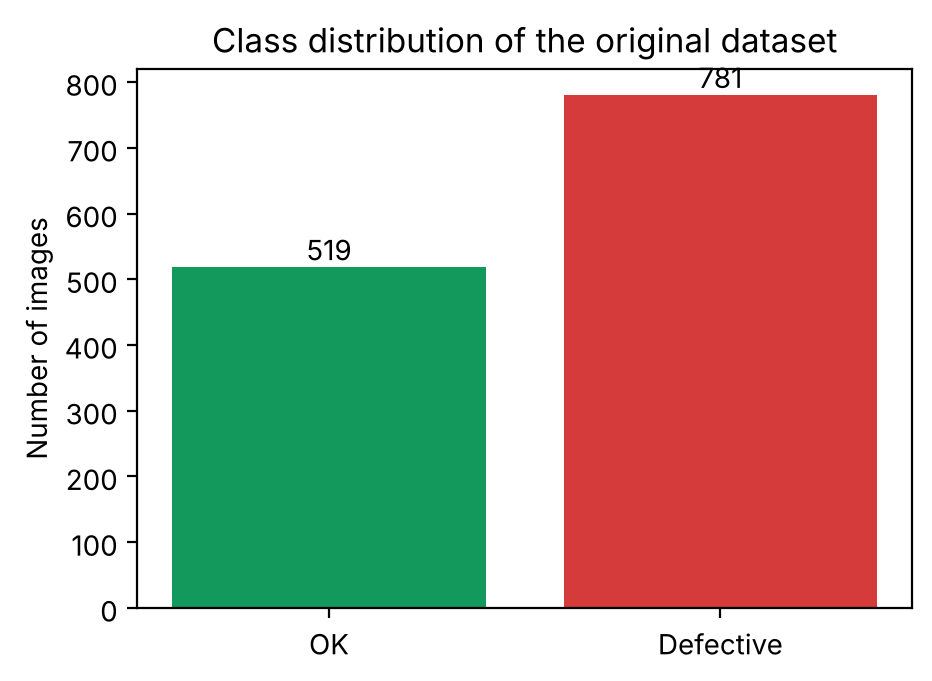

Ratio Defective : OK = 1.50 : 1
Ratio OK : Defective = 0.66 : 1


In [5]:
counts = df["class_name"].value_counts().reindex(["OK", "Defective"])

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#13995B", "#D63B3B"])
ax.bar_label(bars)
ax.set_ylabel("Number of images")
ax.set_title("Class distribution of the original dataset")
plt.show()

print(f"Ratio Defective : OK = {counts['Defective'] / counts['OK']:.2f} : 1")
print(f"Ratio OK : Defective = {counts['OK'] / counts['Defective']:.2f} : 1")

### Observations
The original data are only mildly imbalanced, and **defects are the larger class**. On a real production line defects are rare, so Section 5 creates controlled imbalance in which defects become the minority.

## 3.2 Preview Samples from Both Classes

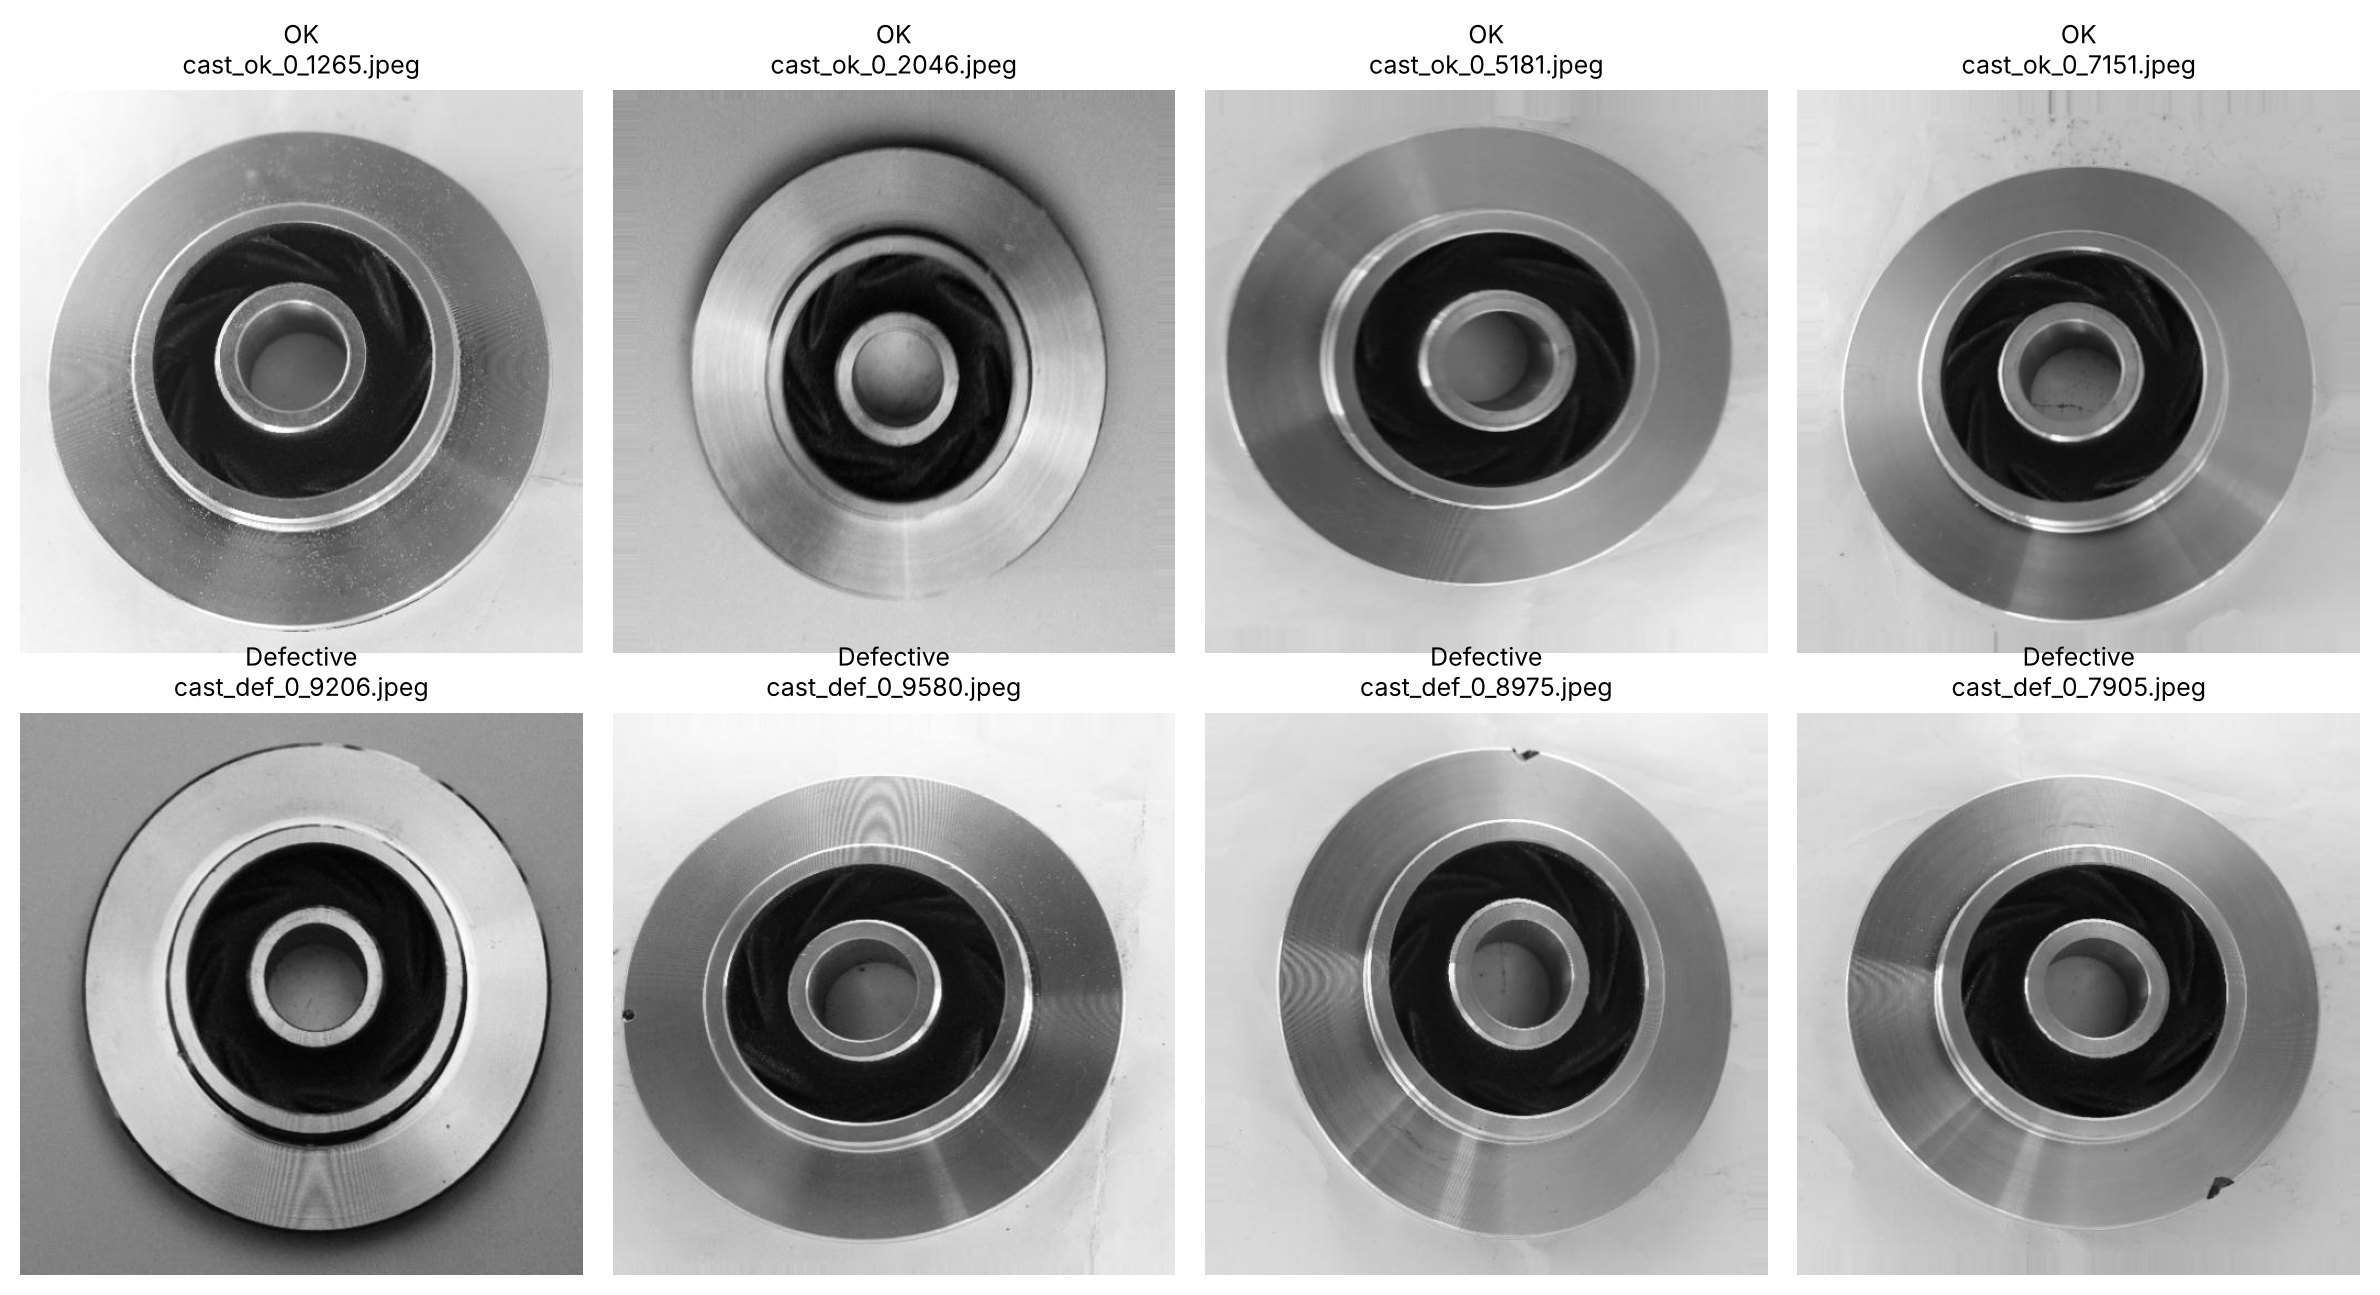

In [6]:
rng = np.random.RandomState(3)
ok_idx = rng.choice(df.index[df.label == 0], 4, replace=False)
def_idx = rng.choice(df.index[df.label == 1], 4, replace=False)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
for ax, idx in zip(axes.flatten(), np.concatenate([ok_idx, def_idx])):
    img = cv2.imread(df.path[idx], cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{df.class_name[idx]}\n{df.filename[idx]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3.3 Image Size and Colour Channels

The files are stored as 3-channel JPEGs. If the three channels are identical, the images are really grayscale and one channel is enough.

In [7]:
sizes, identical = set(), 0
for path in df.path:
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    sizes.add(img.shape)
    b, g, r = cv2.split(img)
    identical += int(np.abs(b.astype(int) - g).max() <= 2 and np.abs(g.astype(int) - r).max() <= 2)

print("Image shapes found:", sizes)
print(f"Images whose 3 channels are (almost) identical: {identical} of {len(df)}")

Image shapes found: {(512, 512, 3)}
Images whose 3 channels are (almost) identical: 1300 of 1300


## 3.4 Brightness per Class

A difference in average brightness between classes would be a possible **shortcut** for the models, so it is checked here.

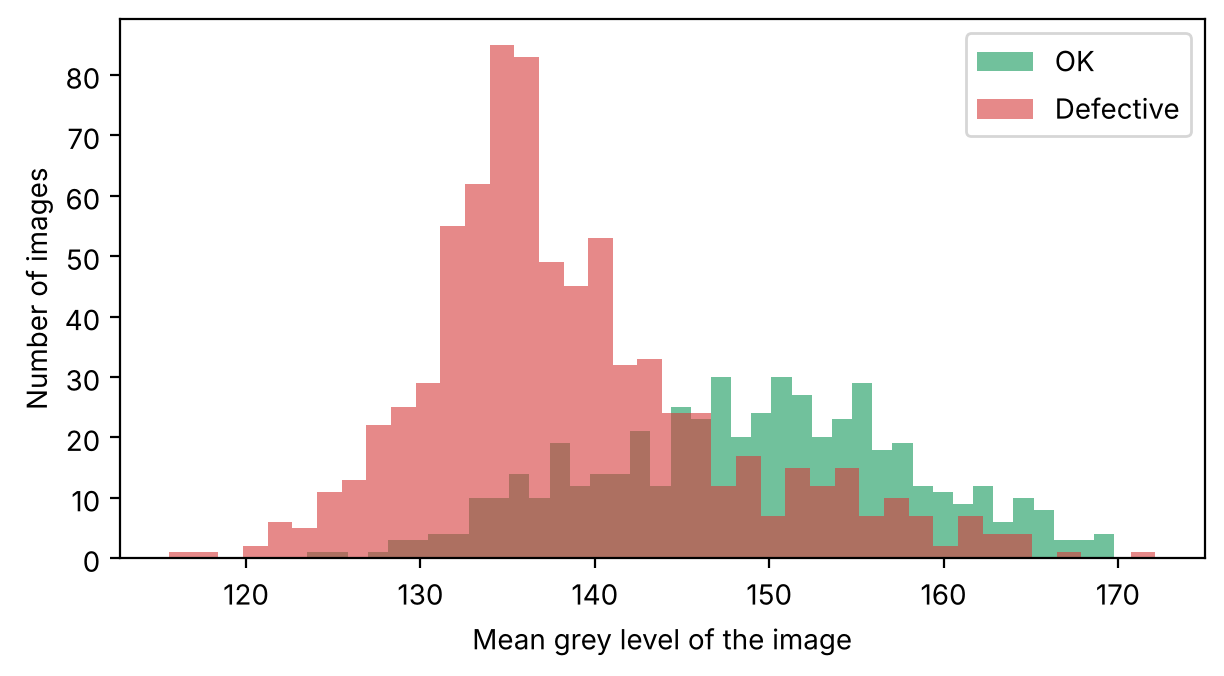

,mean,std
class_name,,
Defective,138.6,8.6
OK,149.0,9.1


Mann-Whitney U test p-value = 9.55e-76


In [8]:
gray_small = np.stack([cv2.resize(cv2.imread(p, cv2.IMREAD_GRAYSCALE), (64, 64),
                                  interpolation=cv2.INTER_AREA) for p in df.path])
df["mean_intensity"] = gray_small.reshape(len(df), -1).mean(axis=1)

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, colour in ((0, "#13995B"), (1, "#D63B3B")):
    ax.hist(df.mean_intensity[df.label == label], bins=40, alpha=0.6, color=colour,
            label=CLASS_NAMES[label])
ax.set_xlabel("Mean grey level of the image")
ax.set_ylabel("Number of images")
ax.legend()
plt.show()

summary = df.groupby("class_name")["mean_intensity"].agg(["mean", "std"]).round(1)
stat, p = mannwhitneyu(df.mean_intensity[df.label == 0], df.mean_intensity[df.label == 1])
display(summary)
print(f"Mann-Whitney U test p-value = {p:.2e}")

### Observations
OK images are slightly brighter on average. The difference is statistically significant, so brightness alone carries some class information. The report lists this as a limitation (Section 4.8).

## 3.5 Duplicate and Near-Duplicate Check

1. **Exact duplicates:** identical files have the same SHA-256 hash.
2. **Near duplicates:** every image is shrunk to 64 × 64 and compared with every other image using the root-mean-square (RMS) grey-level difference.

In [9]:
hashes = [hashlib.sha256(open(p, "rb").read()).hexdigest() for p in df.path]
print("Exact duplicate files:", len(hashes) - len(set(hashes)))

X = gray_small.reshape(len(df), -1).astype(np.float32)
sq = (X ** 2).sum(axis=1)
d2 = np.maximum(sq[:, None] + sq[None, :] - 2 * X @ X.T, 0) / X.shape[1]
rms = np.sqrt(d2)
np.fill_diagonal(rms, np.inf)
nearest = rms.min(axis=1)

print(f"Nearest-neighbour RMS difference: median {np.median(nearest):.1f}, minimum {nearest.min():.2f}")
i, j = np.where(np.triu(rms < 5, 1))
print("Pairs closer than 5 grey levels:", len(i))
pd.DataFrame({"image_a": df.filename[i].values, "image_b": df.filename[j].values,
              "rms": rms[i, j].round(2)})

Exact duplicate files: 0


Nearest-neighbour RMS difference: median 22.1, minimum 3.85
Pairs closer than 5 grey levels: 2


,image_a,image_b,rms
0,cast_ok_0_4691.jpeg,cast_ok_0_5191.jpeg,3.85
1,cast_ok_0_5326.jpeg,cast_ok_0_6880.jpeg,4.12


# 4. Data Splitting (70 / 15 / 15)

```text
1,300 images
   │  train_test_split(test_size=0.15, stratify=label, random_state=42)
   ├──────────────► TEST        195 images (15%)   used ONCE for final results
   │
1,105 images
   │  train_test_split(test_size=0.15/0.85, stratify=label, random_state=42)
   ├──────────────► VALIDATION  195 images (15%)   tuning, early stopping, thresholds
   └──────────────► TRAINING    910 images (70%)   fitting the models
```

A validation set is needed because hyperparameters, early stopping and threshold moving must be chosen on data the model was not trained on. Choosing them on the test set would leak test information into the model.

In [10]:
train_val, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=42)
train_df, val_df = train_test_split(train_val, test_size=0.15 / 0.85,
                                    stratify=train_val["label"], random_state=42)

# keep each split in file-name order so later random draws are reproducible
train_df, val_df, test_df = (part.sort_values("filename").reset_index(drop=True)
                             for part in (train_df, val_df, test_df))

split_table = pd.DataFrame({
    name: part["class_name"].value_counts().reindex(["OK", "Defective"])
    for name, part in (("Training", train_df), ("Validation", val_df), ("Test", test_df))
}).T
split_table["Total"] = split_table.sum(axis=1)
split_table["Share"] = (split_table["Total"] / len(df) * 100).round(1).astype(str) + "%"
split_table

class_name,OK,Defective,Total,Share
Training,363,547,910,70.0%
Validation,78,117,195,15.0%
Test,78,117,195,15.0%


### Check: no image appears in more than one split

In [11]:
tr, va, te = set(train_df.filename), set(val_df.filename), set(test_df.filename)
print("Train ∩ Val :", len(tr & va))
print("Train ∩ Test:", len(tr & te))
print("Val ∩ Test  :", len(va & te))

saved = pd.read_csv(CFG.output_dir / "tables" / "data_split.csv")
same = set(saved[saved.split == "test"].filename) == te
print("Identical to the split used in the report (data_split.csv):", same)

Train ∩ Val : 0
Train ∩ Test: 0
Val ∩ Test  : 0
Identical to the split used in the report (data_split.csv): True


# 5. Creating Class Imbalance (Training Set Only)

For a ratio *r* (OK : Defective), **all 363 OK** training images are kept and `round(363 / r)` defective images are drawn at random.

| Scenario | OK | Defective |
|---|---|---|
| Natural | 363 | 547 (all) |
| 3 : 1 | 363 | 121 |
| 10 : 1 | 363 | 36 |
| 20 : 1 | 363 | 18 |

The validation and test sets are **never** changed.

In [12]:
def build_scenario(train_df, ratio, seed):
    if ratio == "natural":
        return train_df.copy()
    ok = train_df[train_df.label == 0]
    defective = train_df[train_df.label == 1]
    n_def = int(round(len(ok) / ratio))
    rng = np.random.RandomState(seed)
    chosen = defective.iloc[rng.choice(len(defective), n_def, replace=False)]
    return pd.concat([ok, chosen]).sort_values("filename").reset_index(drop=True)

RATIOS = ["natural", 3, 10, 20]
scenarios = {r: build_scenario(train_df, r, seed=1000) for r in RATIOS}

rows = []
for r, s in scenarios.items():
    n_ok, n_def = (s.label == 0).sum(), (s.label == 1).sum()
    rows.append({"Scenario": r, "OK": n_ok, "Defective": n_def,
                 "OK : Defective": f"{n_ok / n_def:.2f} : 1",
                 "Defect share": f"{n_def / len(s):.1%}"})
pd.DataFrame(rows)

,Scenario,OK,Defective,OK : Defective,Defect share
0,natural,363,547,0.66 : 1,60.1%
1,3,363,121,3.00 : 1,25.0%
2,10,363,36,10.08 : 1,9.0%
3,20,363,18,20.17 : 1,4.7%


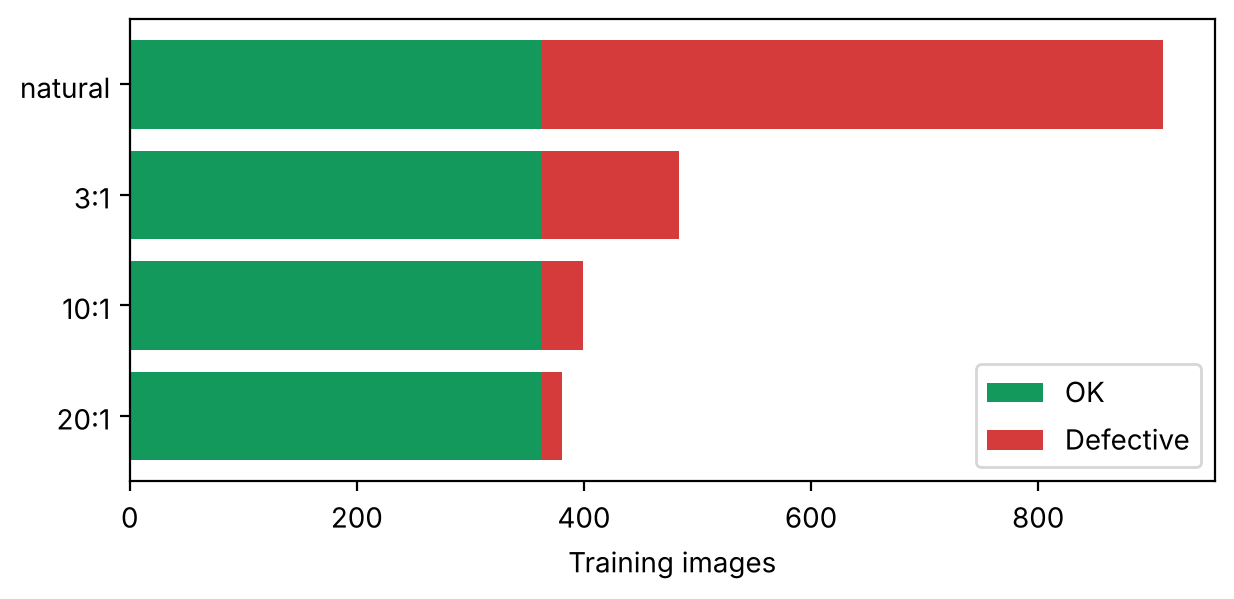

In [13]:
fig, ax = plt.subplots(figsize=(7, 3))
labels = [str(r) if r == "natural" else f"{r}:1" for r in RATIOS]
ok_n = [(scenarios[r].label == 0).sum() for r in RATIOS]
def_n = [(scenarios[r].label == 1).sum() for r in RATIOS]
ax.barh(labels, ok_n, color="#13995B", label="OK")
ax.barh(labels, def_n, left=ok_n, color="#D63B3B", label="Defective")
ax.invert_yaxis()
ax.set_xlabel("Training images")
ax.legend()
plt.show()

# 6. Image Preprocessing

```text
Image → Grayscale → Resize (INTER_AREA) → Gaussian 3×3 (noise removal)
```

Four variants were compared in Ablation A of the report. Gaussian smoothing was kept, while Contrast Limited Adaptive Histogram Equalisation (CLAHE) was tested but did not help.

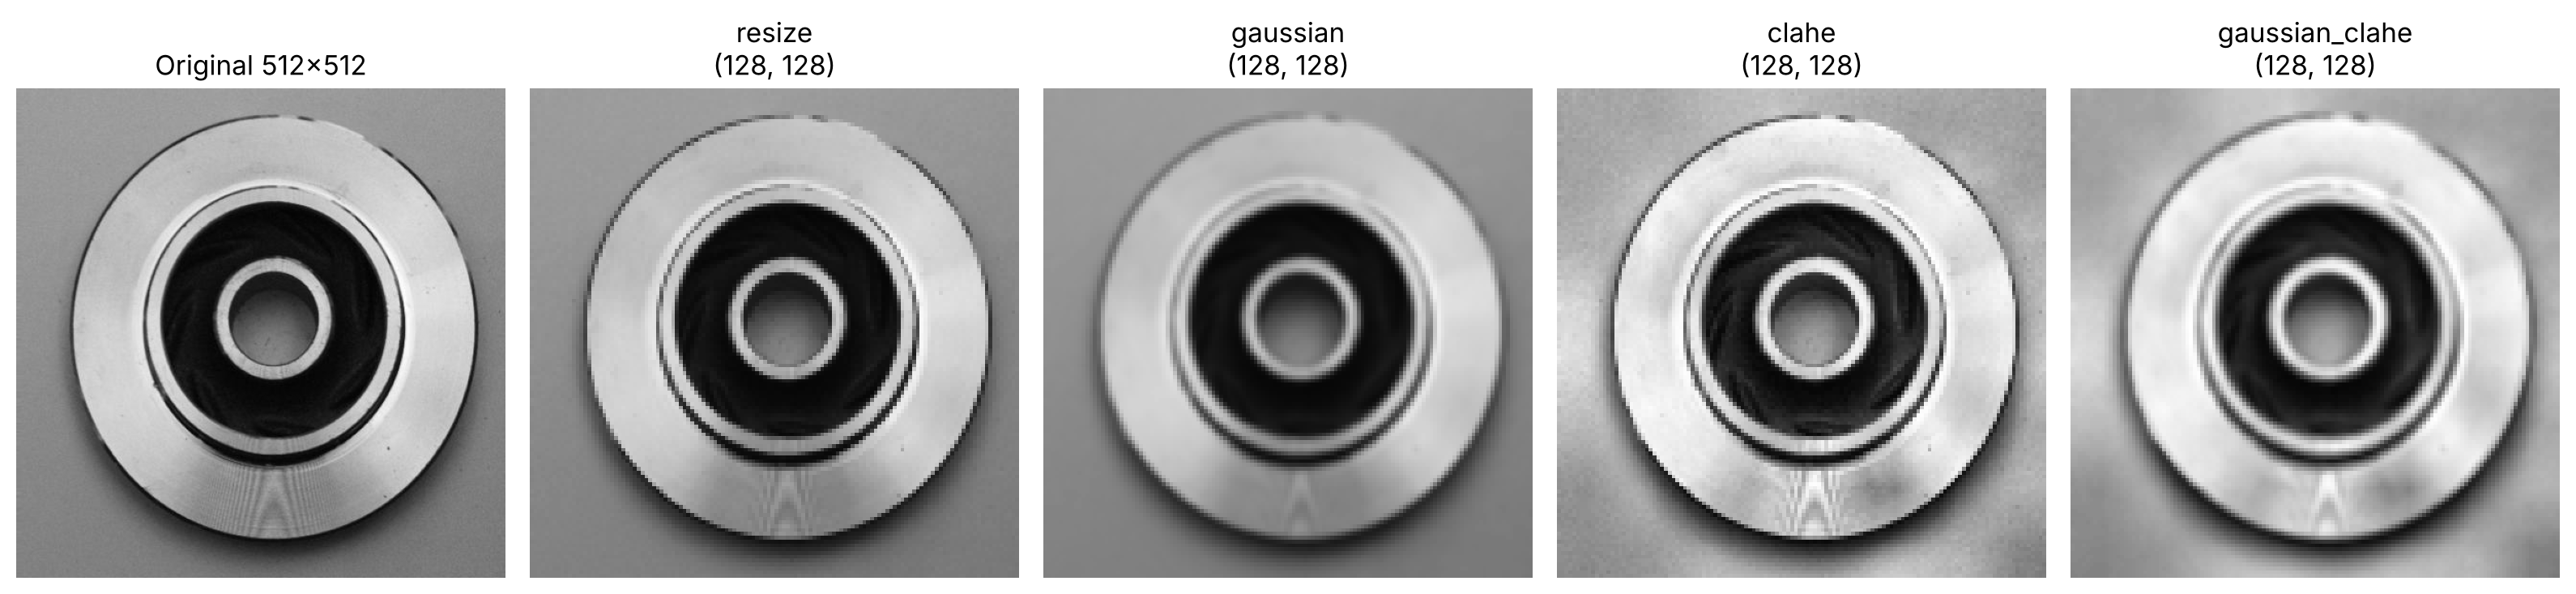

In [14]:
sample_path = df.path[def_idx[0]]
variants = {mode: ImagePreprocessor(128, mode).process_path(sample_path)
            for mode in ("resize", "gaussian", "clahe", "gaussian_clahe")}

fig, axes = plt.subplots(1, 5, figsize=(16, 3.6))
axes[0].imshow(cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE), cmap="gray")
axes[0].set_title("Original 512×512")
for ax, (mode, img) in zip(axes[1:], variants.items()):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{mode}\n{img.shape}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 7. Handcrafted Feature Extraction

| Descriptor | What it captures | Length |
|---|---|---|
| HOG (9 orientations, 8×8 cells, 2×2 blocks) | Edge directions, contours, broken rims | 8,100 |
| Uniform LBP (P = 8, R = 1, 10 bins in each of 4 × 4 tiles) | Micro-texture, pinholes | 160 |
| GLCM (32 grey levels, distances 1, 2 and 4, four angles averaged, six properties) | Global texture statistics | 18 |
| **Total** | | **8,278** |

The cell below visualises the three descriptors for one image. For readability, its GLCM uses a single distance and prints four properties, while the extractor in the following cell uses all three distances and six properties.

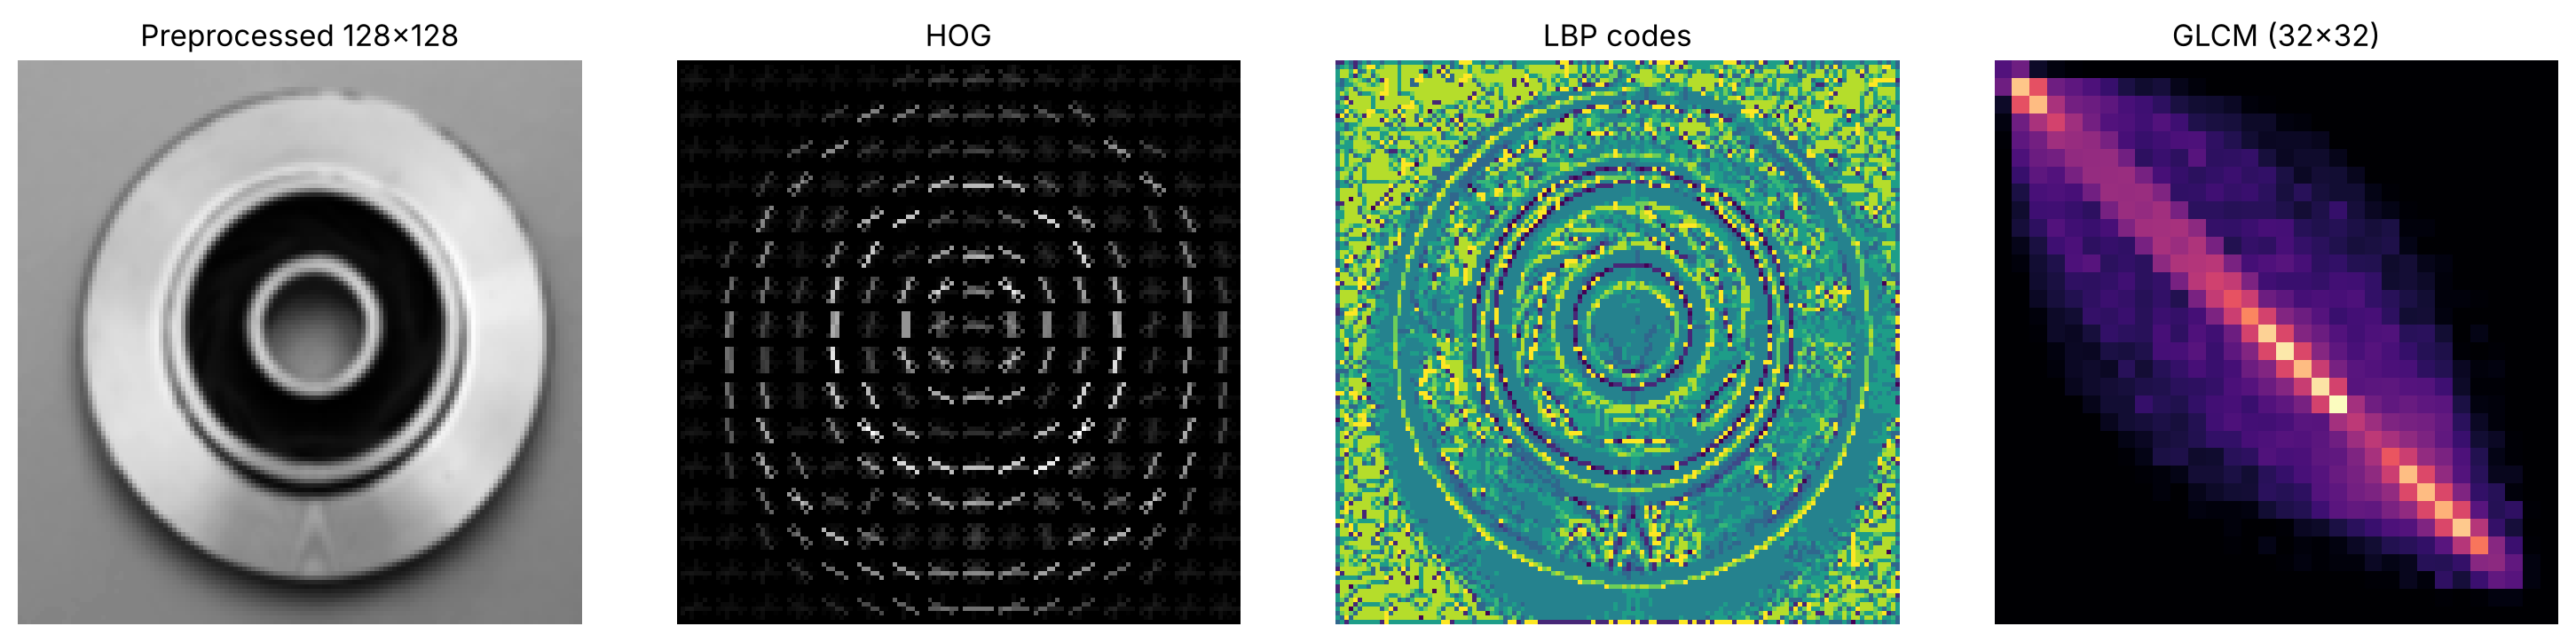

HOG length: 8100
GLCM contrast    : 4.637
GLCM homogeneity : 0.752
GLCM energy      : 0.184
GLCM correlation : 0.958


In [15]:
img = variants["gaussian"]
hog_vec, hog_img = hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                       block_norm="L2-Hys", visualize=True)
lbp = local_binary_pattern(img, 8, 1, "uniform")
glcm = graycomatrix((img // 8).astype(np.uint8), [1], [0, np.pi/4, np.pi/2, 3*np.pi/4],
                    levels=32, symmetric=True, normed=True)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("Preprocessed 128×128")
axes[1].imshow(hog_img ** 0.5, cmap="gray"); axes[1].set_title("HOG")
axes[2].imshow(lbp, cmap="viridis"); axes[2].set_title("LBP codes")
axes[3].imshow(np.log1p(glcm[:, :, 0, :].mean(-1) * 1e4), cmap="magma"); axes[3].set_title("GLCM (32×32)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

print("HOG length:", len(hog_vec))
for prop in ("contrast", "homogeneity", "energy", "correlation"):
    print(f"GLCM {prop:12s}: {graycoprops(glcm, prop).mean():.3f}")

### Extract the feature vector for every image

In [16]:
extractor = HandcraftedFeatureExtractor(ImagePreprocessor(128, "gaussian"))

start = time.time()
features = {p: extractor.extract(p) for p in df.path}
print(f"Extracted {len(features)} feature vectors in {time.time() - start:.0f} s")

def get_features(paths):
    return np.stack([features[p] for p in paths])

print("Feature vector length:", len(next(iter(features.values()))))

Extracted 1300 feature vectors in 11 s
Feature vector length: 8278


### Representation change

Before: `(N, 512, 512)` image pixels → After: `(N, 8278)` feature matrix → after PCA: about `(N, 550)`.

# 8. Scaling and PCA (fitted on the training set only)

`StandardScaler` and `PCA(95% variance)` are **fitted on the training images only** and then applied to validation and test. Fitting them on all images would leak test information.

In [17]:
y_train = train_df.label.values
y_val = val_df.label.values
y_test = test_df.label.values

transformer = FeatureTransformer().fit(get_features(train_df.path))
X_train = transformer.transform(get_features(train_df.path))
X_val = transformer.transform(get_features(val_df.path))
X_test = transformer.transform(get_features(test_df.path))

print("PCA components kept:", transformer.n_components)
print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

PCA components kept: 550
X_train: (910, 550)  X_val: (195, 550)  X_test: (195, 550)


# 9. Classical Models on the Natural Data

Settings tuned on the validation set (Section 4.1 of the report):

| Model | Setting |
|---|---|
| SVM | RBF kernel, C = 10, γ = 10⁻⁴ |
| Logistic Regression | C = 1 |
| k-NN | k = 1, distance weighting |
| Random Forest | 300 trees |

## 9.1 Where these settings come from

`scripts/run_classical.py` and `scripts/run_more_classical.py` tried a grid of settings on the natural training data and scored each one on the **validation set**. The test set was not used. The best settings are loaded below.

In [18]:
tuning_dir = CFG.output_dir / "tables"
print("SVM: C and gamma")
display(pd.read_csv(tuning_dir / "svm_tuning.csv").head(5).round(4))
print("Logistic Regression: C")
display(pd.read_csv(tuning_dir / "logreg_tuning.csv").rename(columns={"param": "C"}).head(3).round(4))
print("k-NN: number of neighbours k")
display(pd.read_csv(tuning_dir / "knn_tuning.csv").rename(columns={"param": "k"}).head(3).round(4))

SVM: C and gamma


,C,gamma,val_balanced_accuracy,val_roc_auc,val_f1_defective
0,10.0,0.0001,0.9722,0.9934,0.9739
1,100.0,0.0001,0.9722,0.9934,0.9739
2,100.0,1e-05,0.9701,0.9886,0.9692
3,10.0,scale,0.9658,0.9934,0.9697
4,100.0,scale,0.9658,0.9934,0.9697


Logistic Regression: C


,C,val_balanced_accuracy,val_roc_auc
0,1.0,0.9701,0.9869
1,0.1,0.9573,0.9863
2,10.0,0.9573,0.9773


k-NN: number of neighbours k


,k,val_balanced_accuracy,val_roc_auc
0,1,0.9103,0.9103
1,9,0.8996,0.9484
2,3,0.8974,0.9446


- *C* = 10 and *C* = 100 give the same SVM result, so the smaller value is kept.
- For k-NN, *k* = 1 has the highest validation balanced accuracy, although larger *k* gives a higher ROC-AUC. This choice matters under imbalance (Section 16.5).

## 9.2 Train the four classical models

In [19]:
METRICS = ["accuracy", "balanced_accuracy", "recall_defective", "recall_ok", "mcc", "roc_auc"]

def classical_models(seed=42):
    return {"SVM": SVMClassifier(C=10, gamma=1e-4, seed=seed),
            "Logistic Regression": LogisticRegressionModel(C=1.0, seed=seed),
            "k-NN": KNNModel(k=1, seed=seed),
            "Random Forest": RandomForestModel(seed=seed)}

def evaluate(model, X, y, threshold=0.5):
    return Evaluator.compute(y, model.predict_proba(X), threshold)

natural_results, natural_models = {}, {}
for name, model in classical_models().items():
    model.fit(X_train, y_train)
    natural_models[name] = model
    natural_results[name] = evaluate(model, X_test, y_test)

pd.DataFrame(natural_results).T[METRICS].round(3)

,accuracy,balanced_accuracy,recall_defective,recall_ok,mcc,roc_auc
SVM,0.974,0.974,0.974,0.974,0.947,0.998
Logistic Regression,0.964,0.966,0.957,0.974,0.926,0.995
k-NN,0.923,0.934,0.880,0.987,0.852,0.934
Random Forest,0.928,0.912,0.991,0.833,0.854,0.973


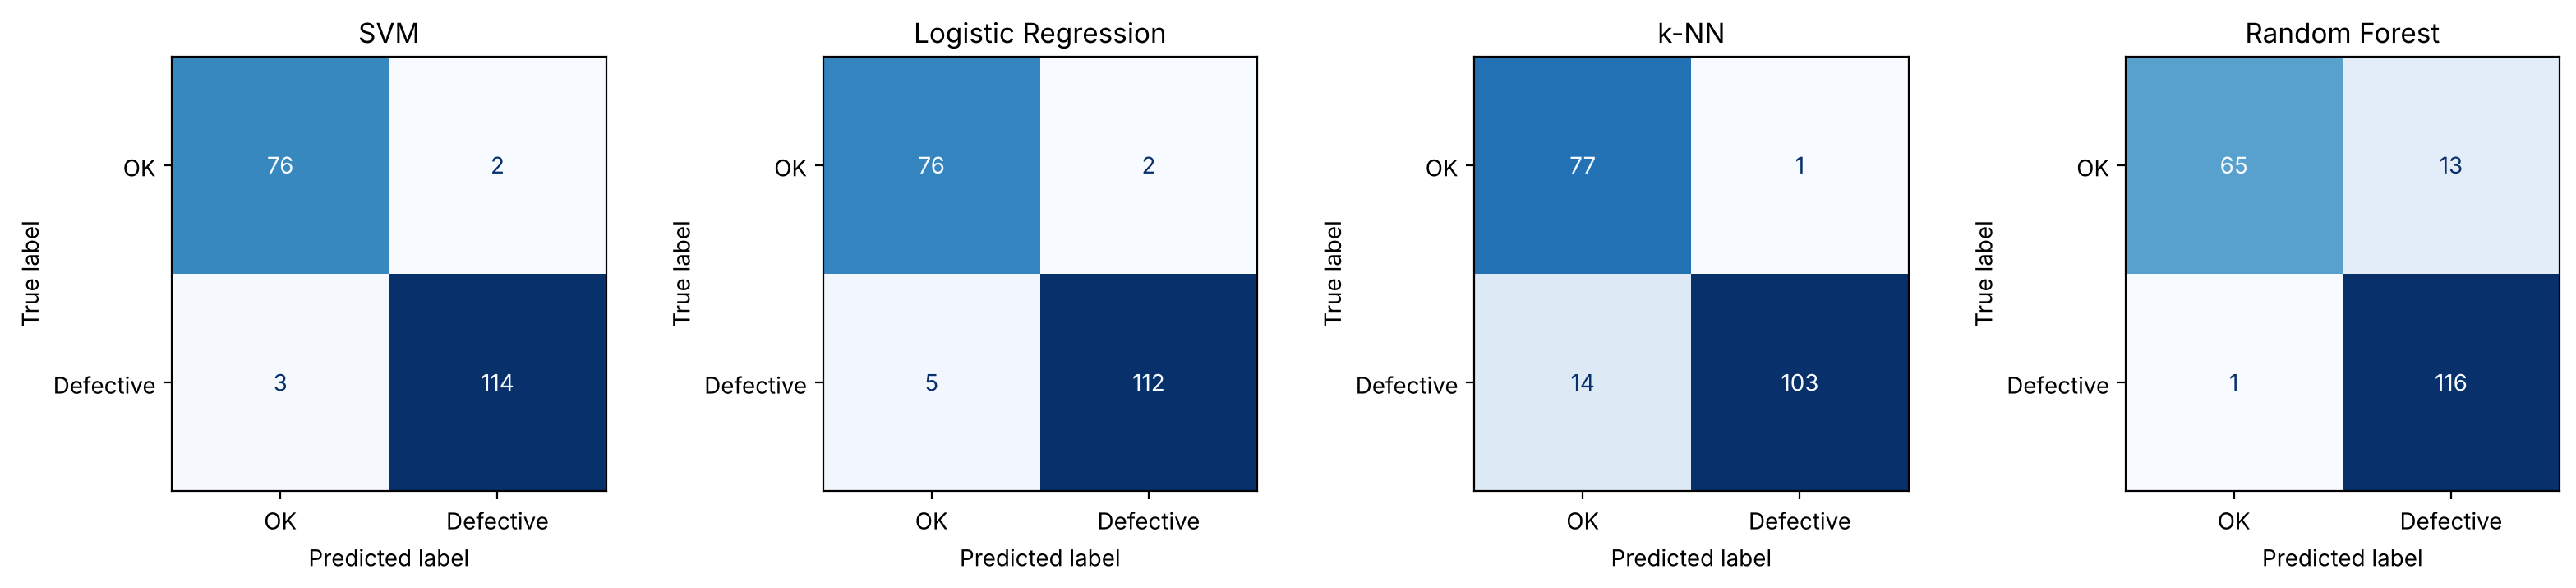

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, m) in zip(axes, natural_results.items()):
    ConfusionMatrixDisplay(np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]),
                           display_labels=["OK", "Defective"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Observations
- On the natural data, the SVM performed best, with a balanced accuracy of 0.974 and an ROC-AUC of 0.998. Logistic Regression was close behind at 0.966.
- The Random Forest found almost every defect (defect recall 0.991) but rejected more good castings (OK recall 0.833).
- k-NN with one neighbour had the lowest ROC-AUC (0.934), because it gives only scores of 0 or 1.

# 10. Effect of Class Imbalance (20 : 1)

Now the models are trained on only **18 defective** images next to 363 OK images. The scaler and PCA are refitted on this smaller training set.

In [21]:
train_20 = scenarios[20]
y_train_20 = train_20.label.values
tf_20 = FeatureTransformer().fit(get_features(train_20.path))
X_train_20 = tf_20.transform(get_features(train_20.path))
X_val_20 = tf_20.transform(get_features(val_df.path))
X_test_20 = tf_20.transform(get_features(test_df.path))

imbalanced_results = {}
for name, model in classical_models().items():
    model.fit(X_train_20, y_train_20)
    imbalanced_results[name] = evaluate(model, X_test_20, y_test)

pd.DataFrame(imbalanced_results).T[METRICS].round(3)

,accuracy,balanced_accuracy,recall_defective,recall_ok,mcc,roc_auc
SVM,0.472,0.560,0.120,1.0,0.227,0.923
Logistic Regression,0.477,0.564,0.128,1.0,0.236,0.917
k-NN,0.436,0.530,0.060,1.0,0.158,0.530
Random Forest,0.400,0.500,0.000,1.0,0.000,0.346


### The accuracy trap

Compare **accuracy** with **defect recall**. A model can accept almost every part and still look acceptable on accuracy while missing most defects. Balanced accuracy and defect recall reveal the problem. ROC-AUC stays high for the SVM and Logistic Regression: they still **rank** defects above good parts, but the 0.5 threshold is in the wrong place.

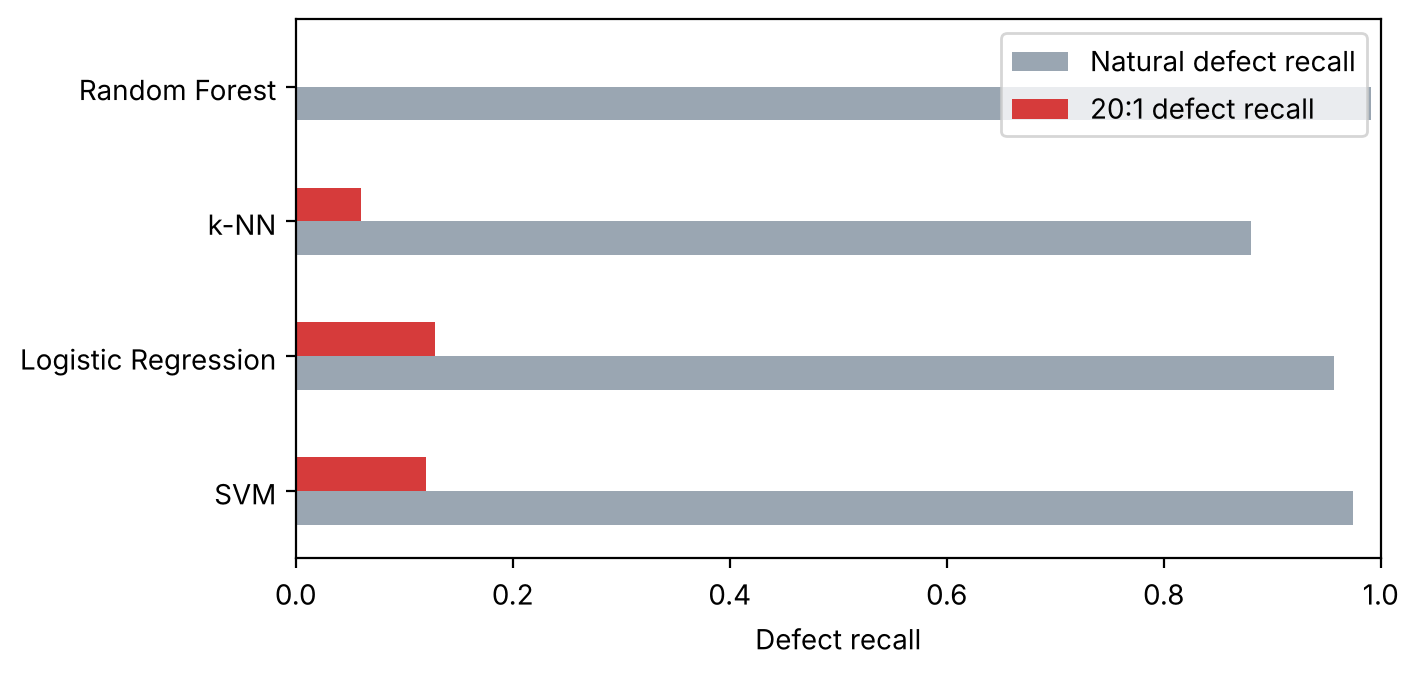

,Natural BA,20:1 BA,Natural defect recall,20:1 defect recall
SVM,0.974,0.560,0.974,0.120
Logistic Regression,0.966,0.564,0.957,0.128
k-NN,0.934,0.530,0.880,0.060
Random Forest,0.912,0.500,0.991,0.000


In [22]:
compare = pd.DataFrame({
    "Natural BA": {k: v["balanced_accuracy"] for k, v in natural_results.items()},
    "20:1 BA": {k: v["balanced_accuracy"] for k, v in imbalanced_results.items()},
    "Natural defect recall": {k: v["recall_defective"] for k, v in natural_results.items()},
    "20:1 defect recall": {k: v["recall_defective"] for k, v in imbalanced_results.items()},
}).round(3)

compare[["Natural defect recall", "20:1 defect recall"]].plot.barh(
    figsize=(7, 3.5), color=["#9AA6B2", "#D63B3B"])
plt.xlabel("Defect recall")
plt.xlim(0, 1)
plt.show()
compare

# 11. Imbalance-Handling Methods (SVM and Logistic Regression, 20 : 1)

| Method | Level | What it does |
|---|---|---|
| Class weighting | Algorithm | Mistakes on the rare class cost more: w_c = N / (2 N_c) |
| Random oversampling (ROS) | Data | Duplicate defects until classes are equal |
| SMOTE | Data | Create synthetic defects between real ones |
| Random undersampling (RUS) | Data | Remove OK images until classes are equal |
| Threshold moving | Decision | Keep the model, choose the threshold that maximises validation BA |

Resampling is applied to the **training data only**, after PCA. Augmentation oversampling creates new images, so it is applied only to the neural models in the full experiment (Section 14 onwards).

In [23]:
def run_methods(model_factory, X_tr, y_tr, X_va, X_te, seed=1000):
    out = {}
    # baseline
    base = model_factory().fit(X_tr, y_tr)
    out["None"] = evaluate(base, X_te, y_test)
    # class weighting
    m = model_factory().fit(X_tr, y_tr, class_weight=balanced_class_weights(y_tr))
    out["Class weighting"] = evaluate(m, X_te, y_test)
    # resampling
    k = min(5, int((y_tr == 1).sum()) - 1)
    samplers = {"ROS": RandomOverSampler(random_state=seed),
                "SMOTE": SMOTE(k_neighbors=k, random_state=seed),
                "RUS": RandomUnderSampler(random_state=seed)}
    for name, sampler in samplers.items():
        X_rs, y_rs = sampler.fit_resample(X_tr, y_tr)
        m = model_factory().fit(X_rs, y_rs)
        out[name] = evaluate(m, X_te, y_test)
    # threshold moving: reuse the baseline, tune the threshold on validation data
    t = ThresholdOptimizer().fit(y_val, base.predict_proba(X_va))
    out[f"Threshold moving (t = {t:.2f})"] = evaluate(base, X_te, y_test, threshold=t)
    return pd.DataFrame(out).T[["balanced_accuracy", "recall_defective", "recall_ok", "mcc"]].round(3)

print("SVM, 20:1")
display(run_methods(lambda: SVMClassifier(C=10, gamma=1e-4), X_train_20, y_train_20, X_val_20, X_test_20))
print("Logistic Regression, 20:1")
display(run_methods(lambda: LogisticRegressionModel(C=1.0), X_train_20, y_train_20, X_val_20, X_test_20))

SVM, 20:1


,balanced_accuracy,recall_defective,recall_ok,mcc
None,0.560,0.120,1.000,0.227
Class weighting,0.560,0.120,1.000,0.227
ROS,0.560,0.120,1.000,0.227
SMOTE,0.607,0.214,1.000,0.313
RUS,0.652,0.444,0.859,0.318
Threshold moving (t = 0.30),0.872,0.821,0.923,0.729


Logistic Regression, 20:1


,balanced_accuracy,recall_defective,recall_ok,mcc
None,0.564,0.128,1.000,0.236
Class weighting,0.611,0.222,1.000,0.320
ROS,0.611,0.222,1.000,0.320
SMOTE,0.611,0.222,1.000,0.320
RUS,0.709,0.547,0.872,0.423
Threshold moving (t = 0.01),0.778,0.581,0.974,0.567


### Observations
- **Threshold moving** gives the largest gain for both models, because their scores still rank defects higher than good parts.
- For the tuned SVM, **class weighting and ROS change nothing**: the training data are already separated with no errors, so there is nothing for the extra weight to act on (report Section 4.4.5, and Section 16.5 below).

# 12. Neural Model 1: MobileNetV2 Transfer Learning

```text
Gray 224×224 → replicate to 3 channels → MobileNetV2 (ImageNet, FROZEN)
            → 1,280-D embedding → Dense 128 → Dropout 0.3 → Sigmoid
```

The frozen backbone gives the same embedding every time, so embeddings are computed once (or loaded from `outputs/cache`) and only the small head is trained.

In [24]:
import tensorflow as tf
from casting_imbalance.models.neural import MobileNetV2Embedder, TransferHead, set_global_seed
print("TensorFlow:", tf.__version__)

cache = CFG.output_dir / "cache" / "mobilenet_gaussian.npz"
if cache.exists():
    data = np.load(cache, allow_pickle=True)
    by_name = {os.path.basename(p): e for p, e in zip(data["paths"], data["emb"])}
    print("Loaded cached embeddings:", data["emb"].shape)
else:
    start = time.time()
    images = ImagePreprocessor(224, "gaussian").process_many(df.path)
    emb = MobileNetV2Embedder().embed(images)
    by_name = dict(zip(df.filename, emb))
    print(f"Computed embeddings in {time.time() - start:.0f} s:", emb.shape)

def embeddings(frame):
    return np.stack([by_name[f] for f in frame.filename])

TensorFlow: 2.21.0


Loaded cached embeddings: (1300, 1280)


In [25]:
mnv2_results = {}
for ratio in ("natural", 20):
    tr = scenarios[ratio]
    set_global_seed(1000)
    head = TransferHead(seed=1000).fit(embeddings(tr), tr.label.values,
                                       X_val=embeddings(val_df), y_val=y_val)
    p_val, p_test = head.predict_proba(embeddings(val_df)), head.predict_proba(embeddings(test_df))
    label = "Natural" if ratio == "natural" else "20:1"
    mnv2_results[f"{label}, no handling"] = Evaluator.compute(y_test, p_test)
    t = ThresholdOptimizer().fit(y_val, p_val)
    mnv2_results[f"{label}, threshold moving (t = {t:.2f})"] = Evaluator.compute(y_test, p_test, t)

pd.DataFrame(mnv2_results).T[METRICS].round(3)

,accuracy,balanced_accuracy,recall_defective,recall_ok,mcc,roc_auc
"Natural, no handling",0.995,0.994,1.000,0.987,0.989,1.000
"Natural, threshold moving (t = 0.84)",0.995,0.994,1.000,0.987,0.989,1.000
"20:1, no handling",0.641,0.701,0.402,1.000,0.460,0.971
"20:1, threshold moving (t = 0.05)",0.908,0.915,0.880,0.949,0.816,0.971


### Observations
- On the natural data, MobileNetV2 misclassified only one of the 195 test images, with a balanced accuracy of 0.994.
- At 20:1 without handling, its defect recall fell to 0.402, while its ROC-AUC stayed at 0.971. Threshold moving (t = 0.05) raised balanced accuracy from 0.701 to 0.915. The pretrained features still separated the classes, and only the default threshold was in the wrong place.

# 13. Neural Model 2: CNN Trained From Scratch

```text
128×128×1 → [Conv 3×3 → BatchNorm → ReLU → MaxPool] × 4 (32, 64, 128, 128 filters)
          → Global Average Pooling → Dropout 0.4 → Sigmoid
```

Training takes 2 to 10 minutes on a CPU, depending on the computer. Set `RUN_CNN = False` to skip it.

In [26]:
from casting_imbalance.models.neural import SimpleCNN

SimpleCNN(seed=1000).build().summary()

Model: "simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 241,441 (943.13 KB)

 Trainable params: 240,737 (940.38 KB)

 Non-trainable params: 704 (2.75 KB)

In [27]:
RUN_CNN = True

if RUN_CNN:
    pre = ImagePreprocessor(128, "gaussian")
    X_tr_img = pre.process_many(train_df.path)
    X_va_img = pre.process_many(val_df.path)
    X_te_img = pre.process_many(test_df.path)

    set_global_seed(1000)
    start = time.time()
    cnn = SimpleCNN(seed=1000).fit(X_tr_img, y_train, X_val=X_va_img, y_val=y_val)
    print(f"Trained in {time.time() - start:.0f} s")
    cnn_metrics = Evaluator.compute(y_test, cnn.predict_proba(X_te_img))
    display(pd.Series(cnn_metrics)[METRICS].round(3).to_frame("CNN, natural data"))

Trained in 625 s


,"CNN, natural data"
accuracy,0.892
balanced_accuracy,0.897
recall_defective,0.872
recall_ok,0.923
mcc,0.783
roc_auc,0.969


### Observations
- Trained from scratch on 910 images, the CNN reached a balanced accuracy of 0.897 on the natural data, clearly below MobileNetV2 (0.994) and the SVM (0.974). Learning features from zero needs more images than this dataset provides.
- Training took about 10 minutes on a CPU, against a few seconds for the MobileNetV2 head and less than a second for the SVM (Section 17).

# 14. Full Experiment: Loading Every Run

Sections 9 to 13 trained each model once to show how the pipeline works. The final study repeats every **model × training ratio × handling method** combination with different random sub-samples of the defects:

| Script | What it runs |
|---|---|
| `scripts/run_classical.py` | SVM and Logistic Regression, plus Ablations A and B |
| `scripts/run_more_classical.py` | k-NN and Random Forest, plus Ablation D |
| `scripts/run_svm_c_ablation.py` | Ablation C (SVM penalty *C*) |
| `scripts/run_mobilenet.py` | MobileNetV2 head |
| `scripts/run_cnn.py` | CNN trained from scratch |

Each run saves one row of test and validation metrics in `outputs/tables/results_*.csv`. These runs take several hours on a CPU, so the notebook loads the saved rows and performs **all of the analysis here**: averaging, statistical tests, tables and figures. Sections 14 to 19 follow the order of Section 4 of the report.

In [28]:
from scipy import stats
from sklearn.metrics import confusion_matrix, roc_curve, precision_recall_curve
from IPython.display import display
from casting_imbalance.experiment import summarise
from casting_imbalance.plotting import (MODEL_COLORS, MODEL_LABELS, MODEL_SHORT,
                                        METHOD_COLORS, METHOD_LABELS, style_axes)

TAB = CFG.output_dir / "tables"
raw = pd.concat([pd.read_csv(TAB / f"results_{name}.csv")
                 for name in ("classical", "classical_extra", "mobilenet", "cnn")], ignore_index=True)
svm_c = pd.read_csv(TAB / "results_svm_c.csv")
for frame in (raw, svm_c):
    frame["ratio"] = frame["ratio"].astype(str)

def experiment_block(tag):
    if tag == "main":
        return "Main experiment"
    return {"pre": "Ablation A: preprocessing", "feat": "Ablation B: feature groups",
            "knnk": "Ablation D: k-NN neighbours"}[tag.split("_")[0]]

runs = raw.tag.map(experiment_block).value_counts()
runs["Ablation C: SVM penalty C"] = len(svm_c)
runs = runs.reindex(["Main experiment", "Ablation A: preprocessing", "Ablation B: feature groups",
                     "Ablation C: SVM penalty C", "Ablation D: k-NN neighbours"])
runs["Total"] = runs.sum()
runs.rename_axis("Experiment block").to_frame("Runs")

,Runs
Experiment block,
Main experiment,664
Ablation A: preprocessing,160
Ablation B: feature groups,100
Ablation C: SVM penalty C,100
Ablation D: k-NN neighbours,240
Total,1264


In [29]:
# Main experiment: how many repetitions each model received
main_runs = raw[raw.tag == "main"]
print("Repetitions per model and ratio (main experiment)")
main_runs.groupby(["model", "ratio"]).rep.nunique().unstack()[["natural", "3", "10", "20"]]

Repetitions per model and ratio (main experiment)


ratio,natural,3,10,20
model,,,,
CNN,2,3,3,3
KNN,5,5,5,5
LogReg,5,5,5,5
MobileNetV2,5,5,5,5
RandomForest,5,5,5,5
SVM,5,5,5,5


### Average the repetitions

`summarise` (from `casting_imbalance/experiment.py`) groups the runs by experiment, model, ratio and method, and returns the **mean** and **standard deviation** of every metric. Every result below comes from this table.

In [30]:
summary = summarise(raw)
main = summary[summary.tag == "main"].copy()

order = ["SVM", "LogReg", "KNN", "RandomForest", "MobileNetV2", "CNN"]
ratios = ["natural", "3", "10", "20"]
model_names = {"SVM": "SVM", "LogReg": "Logistic Regression", "KNN": "k-NN",
               "RandomForest": "Random Forest", "MobileNetV2": "MobileNetV2", "CNN": "CNN"}
ratio_names = {"natural": "Natural", "3": "3:1", "10": "10:1", "20": "20:1"}
ratio_ticks = {"natural": "Natural\n(0.66:1)", "3": "3:1", "10": "10:1", "20": "20:1"}

def row(model, ratio, method):
    # mean results of one model, training ratio and handling method
    return main[(main.model == model) & (main.ratio == ratio) & (main.method == method)].iloc[0]

print("Averaged combinations in the main experiment:", len(main))
main[["model", "ratio", "method", "balanced_accuracy", "balanced_accuracy_sd",
      "recall_defective", "recall_ok", "mcc", "roc_auc"]].head(8).round(3)

Averaged combinations in the main experiment: 140


,model,ratio,method,balanced_accuracy,balanced_accuracy_sd,recall_defective,recall_ok,mcc,roc_auc
0,SVM,natural,none,0.974,0.000,0.974,0.974,0.947,0.998
1,SVM,natural,class_weight,0.974,0.000,0.974,0.974,0.947,0.998
2,SVM,natural,random_oversampling,0.974,0.000,0.974,0.974,0.947,0.998
3,SVM,natural,smote,0.974,0.004,0.961,0.987,0.941,0.998
4,SVM,natural,random_undersampling,0.959,0.007,0.935,0.982,0.907,0.996
5,SVM,natural,threshold_moving,0.974,0.000,0.974,0.974,0.947,0.998
6,SVM,3,none,0.909,0.017,0.827,0.990,0.801,0.983
7,SVM,3,class_weight,0.909,0.017,0.827,0.990,0.801,0.983


# 15. Effect of Class Imbalance Without Handling

This section answers the first question of the study: **what happens to each model when defects become rare and nothing is done about it?**

## 15.1 Performance on the Natural Data

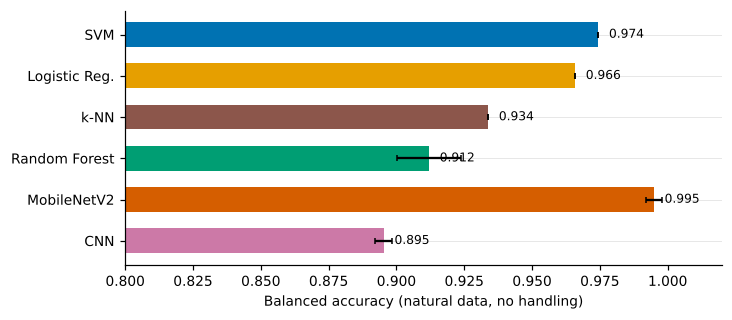

In [31]:
nat = main[(main.ratio == "natural") & (main.method == "none")].set_index("model").reindex(order)
fig, ax = plt.subplots(figsize=(7, 3))
ypos = np.arange(len(order))[::-1]
ax.barh(ypos, nat.balanced_accuracy, xerr=nat.balanced_accuracy_sd, capsize=2, height=0.6,
        color=[MODEL_COLORS[m] for m in order])
for y_, v in zip(ypos, nat.balanced_accuracy):
    ax.text(v + 0.004, y_, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(ypos, [MODEL_SHORT[m] for m in order])
ax.set_xlim(0.8, 1.02)
ax.set_xlabel("Balanced accuracy (natural data, no handling)")
style_axes(ax)
plt.show()

### Observations
All six models work well when defects are plentiful. MobileNetV2 is the strongest, followed by the SVM and Logistic Regression. The CNN trained from scratch is the weakest, because 910 training images are not enough to learn strong features from zero.

## 15.2 Performance as Defects Become Rarer (Figure 27 of the report)

In [32]:
# One row per model and training ratio, using the runs with no imbalance handling
rows = []
for m in order:
    for r in ratios:
        d = row(m, r, "none")
        rows.append({
            "Model": model_names[m],
            "Training ratio": ratio_names[r],
            "Accuracy": f"{d.accuracy:.3f}",
            "Balanced accuracy": f"{d.balanced_accuracy:.3f} ± {d.balanced_accuracy_sd:.3f}",
            "Recall Def.": f"{d.recall_defective:.3f}",
            "Recall OK": f"{d.recall_ok:.3f}",
            "MCC": f"{d.mcc:.3f}",
            "ROC-AUC": f"{d.roc_auc:.3f}",
        })
baseline_table = pd.DataFrame(rows)

print("Test performance without imbalance handling (mean over repetitions)")
print("Balanced accuracy is mean ± standard deviation. Test set: 117 Defective, 78 OK.")
(baseline_table.style.hide(axis="index")
 .set_properties(subset=["Model", "Training ratio"], **{"text-align": "left"}))

Test performance without imbalance handling (mean over repetitions)
Balanced accuracy is mean ± standard deviation. Test set: 117 Defective, 78 OK.


Model,Training ratio,Accuracy,Balanced accuracy,Recall Def.,Recall OK,MCC,ROC-AUC
SVM,Natural,0.974,0.974 ± 0.000,0.974,0.974,0.947,0.998
SVM,3:1,0.892,0.909 ± 0.017,0.827,0.990,0.801,0.983
SVM,10:1,0.684,0.736 ± 0.012,0.475,0.997,0.512,0.951
SVM,20:1,0.504,0.586 ± 0.040,0.173,1.000,0.274,0.928
Logistic Regression,Natural,0.964,0.966 ± 0.000,0.957,0.974,0.926,0.995
Logistic Regression,3:1,0.873,0.893 ± 0.012,0.791,0.995,0.771,0.978
Logistic Regression,10:1,0.678,0.732 ± 0.013,0.463,1.000,0.507,0.949
Logistic Regression,20:1,0.490,0.575 ± 0.030,0.150,1.000,0.254,0.921
k-NN,Natural,0.923,0.934 ± 0.000,0.880,0.987,0.852,0.934
k-NN,3:1,0.683,0.734 ± 0.021,0.479,0.990,0.505,0.734


The figure plots three columns of the table against the training ratio.

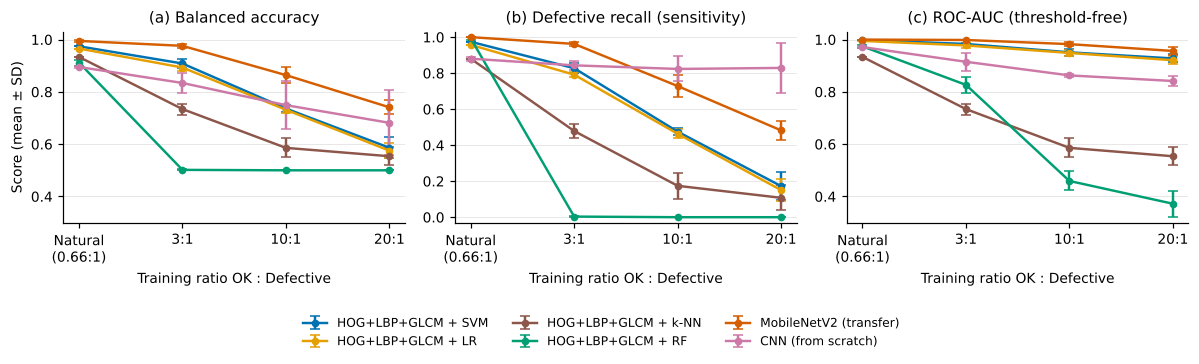

In [33]:
base = main[main.method == "none"]
panels = [("balanced_accuracy", "(a) Balanced accuracy"),
          ("recall_defective", "(b) Defective recall (sensitivity)"),
          ("roc_auc", "(c) ROC-AUC (threshold-free)")]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), sharex=True)
x = np.arange(len(ratios))
for ax, (metric, title) in zip(axes, panels):
    for m in order:
        d = base[base.model == m].set_index("ratio").reindex(ratios)
        ax.errorbar(x, d[metric], yerr=d[f"{metric}_sd"], marker="o", ms=4, capsize=3,
                    color=MODEL_COLORS[m], label=MODEL_LABELS[m], lw=1.6)
    ax.set_xticks(x, [ratio_ticks[r] for r in ratios])
    ax.set_title(title)
    ax.set_ylim(-0.03 if metric == "recall_defective" else 0.3, 1.03)
    ax.set_xlabel("Training ratio OK : Defective")
    style_axes(ax)
axes[0].set_ylabel("Score (mean ± SD)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=8, ncol=3, loc="lower center",
           bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=[0, 0.16, 1, 1])   # leave room for the legend under the panels
plt.show()

### Observations
- Five of the six models lose **defect recall** as the ratio grows, while their OK recall stays close to 1 and reaches 1.000 at 20:1. They learn to pass almost every casting.
- The **Random Forest** fails first. From 3:1 onwards it calls almost every casting OK, so its balanced accuracy drops to the chance level of 0.5.
- The **CNN** goes the other way. It keeps a high defect recall but rejects more and more good castings.

## 15.3 Ranking Versus Decision Threshold

ROC-AUC (panel c above) does not depend on the threshold. The curves below use the first repetition with no handling.

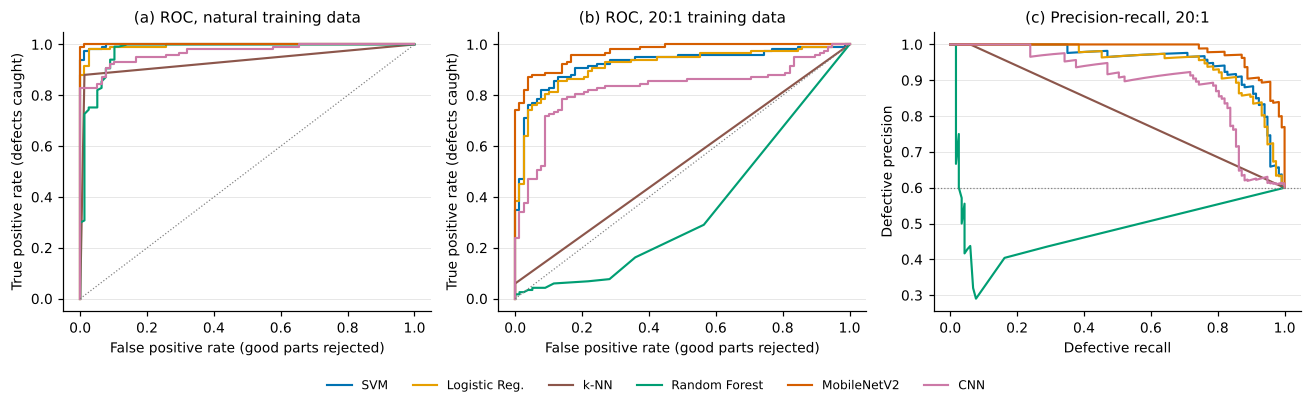

In [34]:
import pickle
probs, histories = {}, {}
for name in ("classical", "classical_extra", "mobilenet", "cnn"):
    with open(CFG.output_dir / f"probs_{name}.pkl", "rb") as f:
        saved = pickle.load(f)
    probs.update(saved["probs"])                     # test-set scores of every run
    histories.update(saved.get("histories", {}))     # training curves of the neural models
    y_true = saved["y_test"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.7))
for ax, ratio, kind in ((axes[0], "natural", "roc"), (axes[1], "20", "roc"), (axes[2], "20", "pr")):
    for m in order:
        p = probs[("main", m, ratio, 0, "none")]
        if kind == "roc":
            fpr, tpr, _ = roc_curve(y_true, p)
            ax.plot(fpr, tpr, color=MODEL_COLORS[m], lw=1.4, label=MODEL_SHORT[m])
        else:
            prec, rec, _ = precision_recall_curve(y_true, p)
            ax.plot(rec, prec, color=MODEL_COLORS[m], lw=1.4, label=MODEL_SHORT[m])
    if kind == "roc":
        ax.plot([0, 1], [0, 1], ":", color="grey", lw=0.8)
        ax.set(xlabel="False positive rate (good parts rejected)", ylabel="True positive rate (defects caught)")
    else:
        ax.axhline(y_true.mean(), ls=":", color="grey", lw=0.8)
        ax.set(xlabel="Defective recall", ylabel="Defective precision")
    style_axes(ax)
axes[0].set_title("(a) ROC, natural training data")
axes[1].set_title("(b) ROC, 20:1 training data")
axes[2].set_title("(c) Precision-recall, 20:1")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=8, ncol=6, loc="lower center", bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

In [35]:
# Random Forest at 20:1: are its scores still in a useful order?
p_rf = probs[("main", "RandomForest", "20", 0, "none")]
print(f"Mean RF score, defective images: {p_rf[y_true == 1].mean():.3f}")
print(f"Mean RF score, OK images:        {p_rf[y_true == 0].mean():.3f}")

Mean RF score, defective images: 0.006
Mean RF score, OK images:        0.007


### Observations
- The SVM, Logistic Regression and MobileNetV2 keep a high ROC-AUC at 20:1. They still **score defects above good castings**, but most defect scores fall below the default threshold of 0.5. Imbalance moved the decision boundary, not the learned features.
- The Random Forest gives almost the same near-zero score to every image, so its scores have no useful order and no threshold can fix it.
- 1-NN gives only scores of 0 or 1, so its ROC curve is a single corner point.

## 15.4 Why Accuracy Is Misleading

In [36]:
svm20 = row("SVM", "20", "none")
rf20 = row("RandomForest", "20", "none")
print(f"Test set (60% defective): SVM accuracy at 20:1 = {svm20.accuracy:.3f}")
print(f"Random Forest calling every image OK still scores {rf20.accuracy:.3f}")

# A production line that looks like the 20:1 training data: 18 defects per 363 + 18 parts
defect_rate = 18 / (363 + 18)
production_accuracy = defect_rate * svm20.recall_defective + (1 - defect_rate) * svm20.recall_ok
print(f"\nDefect rate on the line: {defect_rate:.1%}")
print(f"Expected SVM accuracy on the line: {production_accuracy:.1%}")
print(f"Defects missed per 100 defective castings: {100 * (1 - svm20.recall_defective):.0f}")
print(f"Accuracy of a rule that passes every part: {1 - defect_rate:.1%}")

Test set (60% defective): SVM accuracy at 20:1 = 0.504
Random Forest calling every image OK still scores 0.400

Defect rate on the line: 4.7%
Expected SVM accuracy on the line: 96.1%
Defects missed per 100 defective castings: 83
Accuracy of a rule that passes every part: 95.3%


### Observations
On a production line with 4.7% defects, the 20:1 SVM would look excellent on accuracy while missing most defects. A rule that passes every part also scores about 95%. This is the **accuracy paradox**, and it is why balanced accuracy, the two class recalls and MCC are the main measures.

# 16. Comparing the Imbalance-Handling Methods

## 16.1 Overview of Every Model, Method and Ratio

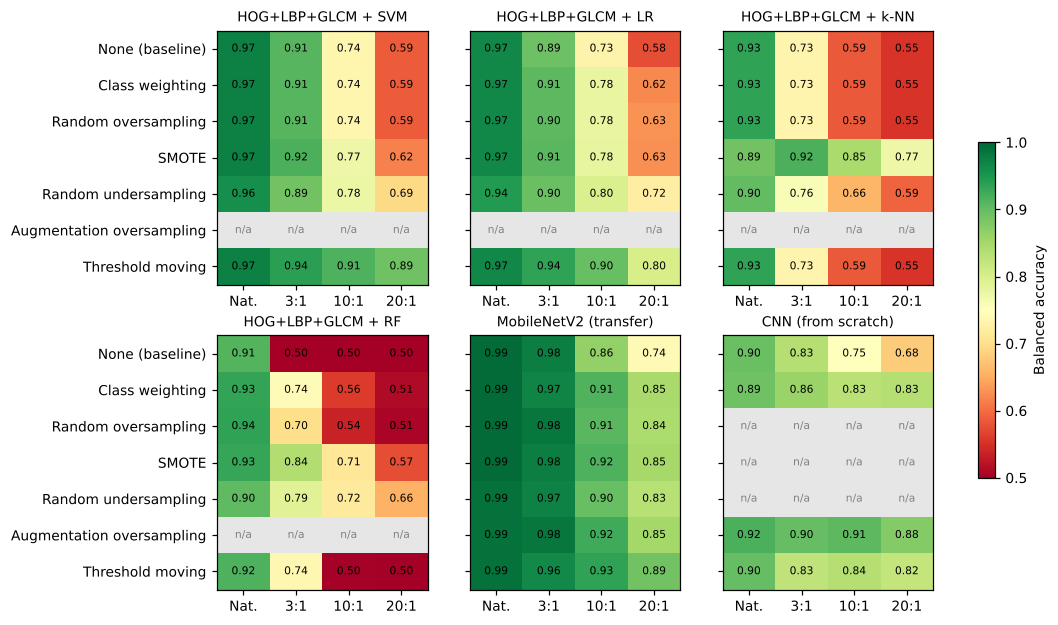

In [37]:
methods = list(METHOD_LABELS)              # same rows in every panel
cmap = plt.get_cmap("RdYlGn").copy()
cmap.set_bad("#E6E6E6")                    # grey = method does not apply to this model

fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.6))
for idx, (ax, m) in enumerate(zip(axes.ravel(), order)):
    grid = (main[main.model == m].pivot(index="method", columns="ratio", values="balanced_accuracy")
            .reindex(index=methods, columns=ratios))
    im = ax.imshow(np.ma.masked_invalid(grid.to_numpy(dtype=float)), cmap=cmap, vmin=0.5, vmax=1.0, aspect="auto")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            v = grid.iat[i, j]
            ax.text(j, i, "n/a" if pd.isna(v) else f"{v:.2f}", ha="center", va="center",
                    fontsize=7, color="#7F7F7F" if pd.isna(v) else "black")
    ax.set_xticks(range(len(ratios)), ["Nat.", "3:1", "10:1", "20:1"])
    ax.set_yticks(range(len(methods)), [METHOD_LABELS[k] for k in methods] if idx % 3 == 0 else [""] * len(methods))
    ax.set_title(MODEL_LABELS[m], fontsize=9)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.6, label="Balanced accuracy")
plt.show()

### Observations
Read each panel row by row from left to right. Green cells stay reliable as defects become rare, and red cells drift towards 0.5. The methods differ little on the natural data, and the differences grow at 10:1 and 20:1.

## 16.2 Statistical Tests (Table 17 of the report)

For each model, the balanced accuracies of the three imbalanced ratios × repetitions form the **blocks** (15 blocks, or 9 for the CNN).

- **Friedman test:** does the handling method matter at all?
- **Wilcoxon signed-rank test** of each method against no handling, with the **Holm correction** for multiple comparisons.

In [38]:
stat_rows = []
imb = raw[(raw.tag == "main") & (raw.ratio != "natural")]
for m in order:
    table = imb[imb.model == m].pivot_table(index=["ratio", "rep"], columns="method", values="balanced_accuracy")
    friedman = stats.friedmanchisquare(*[table[c] for c in table.columns])
    ranks = table.rank(axis=1, ascending=False).mean()          # rank 1 = best in a block
    tests = []
    for method in table.columns.drop("none"):
        diff = table[method] - table["none"]
        p = 1.0 if np.allclose(diff, 0) else stats.wilcoxon(table[method], table["none"]).pvalue
        tests.append((method, diff.mean(), p))
    tests.sort(key=lambda t: t[2])
    running = 0.0
    for i, (method, mean_diff, p) in enumerate(tests):          # Holm step-down correction
        running = max(running, min(1.0, p * (len(tests) - i)))
        stat_rows.append({"model": m, "method": method, "blocks": len(table),
                          "friedman_chi2": friedman.statistic, "friedman_df": table.shape[1] - 1,
                          "friedman_p": friedman.pvalue, "mean_rank": ranks[method],
                          "mean_diff_vs_none": mean_diff, "wilcoxon_p": p, "holm_p": running})
stat_table = pd.DataFrame(stat_rows)
fmt_p = lambda p: "< .001" if p < 0.001 else f"{p:.3f}".lstrip("0")   # APA style p-values

# One summary row per model (Table 17 of the report)
summary_rows = []
for m in order:
    s = stat_table[stat_table.model == m]
    best_ranked = s.sort_values("mean_rank").iloc[0]
    summary_rows.append({"Model": model_names[m],
                         "Friedman χ² (df)": f"{s.friedman_chi2.iloc[0]:.1f} ({s.friedman_df.iloc[0]})",
                         "Friedman p": fmt_p(s.friedman_p.iloc[0]),
                         "Best-ranked method": METHOD_LABELS[best_ranked.method],
                         "Mean rank": f"{best_ranked.mean_rank:.2f}",
                         "Mean ΔBA vs none": f"{best_ranked.mean_diff_vs_none:+.3f}",
                         "Holm-adjusted p": fmt_p(best_ranked.holm_p),
                         "Methods significant": f"{(s.holm_p < 0.05).sum()} of {len(s)}"})
pd.DataFrame(summary_rows).style.hide(axis="index")

Model,Friedman χ² (df),Friedman p,Best-ranked method,Mean rank,Mean ΔBA vs none,Holm-adjusted p,Methods significant
SVM,55.2 (5),< .001,Threshold moving,1.00,+0.171,< .001,2 of 5
Logistic Regression,51.1 (5),< .001,Threshold moving,1.00,+0.145,< .001,5 of 5
k-NN,67.5 (5),< .001,SMOTE,1.00,+0.221,.003,2 of 5
Random Forest,62.9 (5),< .001,SMOTE,1.53,+0.208,< .001,5 of 5
MobileNetV2,19.3 (6),.004,Augmentation oversampling,2.90,+0.059,.011,5 of 6
CNN,14.8 (3),.002,Augmentation oversampling,1.22,+0.139,.012,2 of 3


In [39]:
# Every method against no handling (detailed Wilcoxon and Holm results)
full = stat_table.assign(Model=stat_table.model.map(model_names), Method=stat_table.method.map(METHOD_LABELS))
full = full.assign(**{"Mean rank": full.mean_rank.round(2), "Mean ΔBA vs none": full.mean_diff_vs_none.map("{:+.3f}".format),
                      "Wilcoxon p": full.wilcoxon_p.map(fmt_p), "Holm-adjusted p": full.holm_p.map(fmt_p)})
full[["Model", "Method", "Mean rank", "Mean ΔBA vs none", "Wilcoxon p", "Holm-adjusted p"]].style.hide(axis="index").format(precision=2)

Model,Method,Mean rank,Mean ΔBA vs none,Wilcoxon p,Holm-adjusted p
SVM,Threshold moving,1.00,+0.171,< .001,< .001
SVM,SMOTE,2.47,+0.025,< .001,.003
SVM,Random undersampling,3.53,+0.043,.107,.321
SVM,Class weighting,4.67,+0.000,1.000,1.000
SVM,Random oversampling,4.67,+0.000,1.000,1.000
Logistic Regression,Threshold moving,1.00,+0.145,< .001,< .001
Logistic Regression,Class weighting,4.00,+0.035,< .001,.003
Logistic Regression,SMOTE,3.37,+0.038,< .001,.003
Logistic Regression,Random oversampling,3.57,+0.038,< .001,.003
Logistic Regression,Random undersampling,3.33,+0.072,.003,.003


### Observations
- The Friedman test is significant for all six models, so the choice of handling method matters for every model.
- For every model, the best-ranked method is also significantly better than no handling after the Holm correction.
- A Holm-adjusted *p* of exactly 1 means the method gave **identical predictions** to the baseline. Section 16.5 explains why.

## 16.3 Best Method for Each Model at 20:1

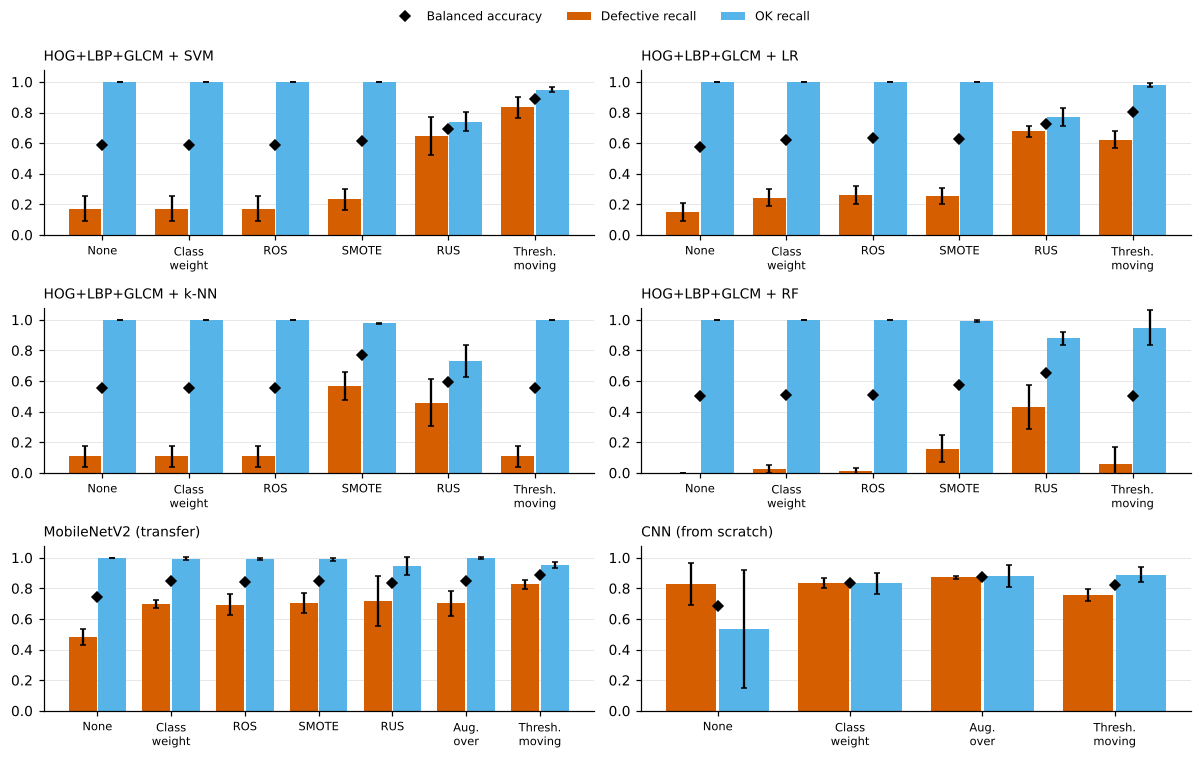

In [40]:
short = {"none": "None", "class_weight": "Class\nweight", "random_oversampling": "ROS", "smote": "SMOTE",
         "random_undersampling": "RUS", "augmentation_oversampling": "Aug.\nover", "threshold_moving": "Thresh.\nmoving"}
sev = main[main.ratio == "20"]
fig, axes = plt.subplots(3, 2, figsize=(11, 6.9))
for ax, m in zip(axes.ravel(), order):
    d = sev[sev.model == m].set_index("method")
    ms = [k for k in METHOD_LABELS if k in d.index]
    x = np.arange(len(ms))
    ax.bar(x - 0.2, d.loc[ms, "recall_defective"], 0.38, yerr=d.loc[ms, "recall_defective_sd"], capsize=2,
           color="#D55E00", label="Defective recall")
    ax.bar(x + 0.2, d.loc[ms, "recall_ok"], 0.38, yerr=d.loc[ms, "recall_ok_sd"], capsize=2,
           color="#56B4E9", label="OK recall")
    ax.plot(x, d.loc[ms, "balanced_accuracy"], "kD", ms=5, label="Balanced accuracy")
    ax.set_xticks(x, [short[k] for k in ms], fontsize=7.5)
    ax.set_ylim(0, 1.08)
    ax.set_title(MODEL_LABELS[m], fontsize=9, loc="left")
    style_axes(ax)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=3, fontsize=8, loc="upper center")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [41]:
# Best method = highest mean test balanced accuracy for each model and ratio
best = (main.sort_values("balanced_accuracy", ascending=False).groupby(["model", "ratio"]).head(1))
best20 = best[best.ratio == "20"].set_index("model").reindex(order)

rows = []
for m in order:
    for label, method in (("Baseline", "none"), (METHOD_LABELS[best20.loc[m, "method"]], best20.loc[m, "method"])):
        d = row(m, "20", method)
        rows.append({"Model": model_names[m] if method == "none" else "", "Handling": label,
                     "Accuracy": d.accuracy, "Precision Def.": d.precision_defective,
                     "Recall Def.": d.recall_defective, "F1 Def.": d.f1_defective,
                     "Recall OK": d.recall_ok, "BA": d.balanced_accuracy})
print("Test performance before and after the best handling method at 20:1 (Table 18 of the report)")
pd.DataFrame(rows).round(3).style.hide(axis="index").format(precision=3)

Test performance before and after the best handling method at 20:1 (Table 18 of the report)


Model,Handling,Accuracy,Precision Def.,Recall Def.,F1 Def.,Recall OK,BA
SVM,Baseline,0.504,1.000,0.173,0.289,1.000,0.586
,Threshold moving,0.880,0.961,0.834,0.892,0.949,0.891
Logistic Regression,Baseline,0.490,1.000,0.150,0.258,1.000,0.575
,Threshold moving,0.765,0.979,0.622,0.760,0.979,0.801
k-NN,Baseline,0.465,1.000,0.108,0.189,1.000,0.554
,SMOTE,0.732,0.974,0.569,0.715,0.977,0.773
Random Forest,Baseline,0.400,0.000,0.000,0.000,1.000,0.500
,Random undersampling,0.610,0.844,0.431,0.558,0.879,0.655
MobileNetV2,Baseline,0.689,1.000,0.482,0.649,1.000,0.741
,Threshold moving,0.878,0.964,0.827,0.890,0.954,0.891


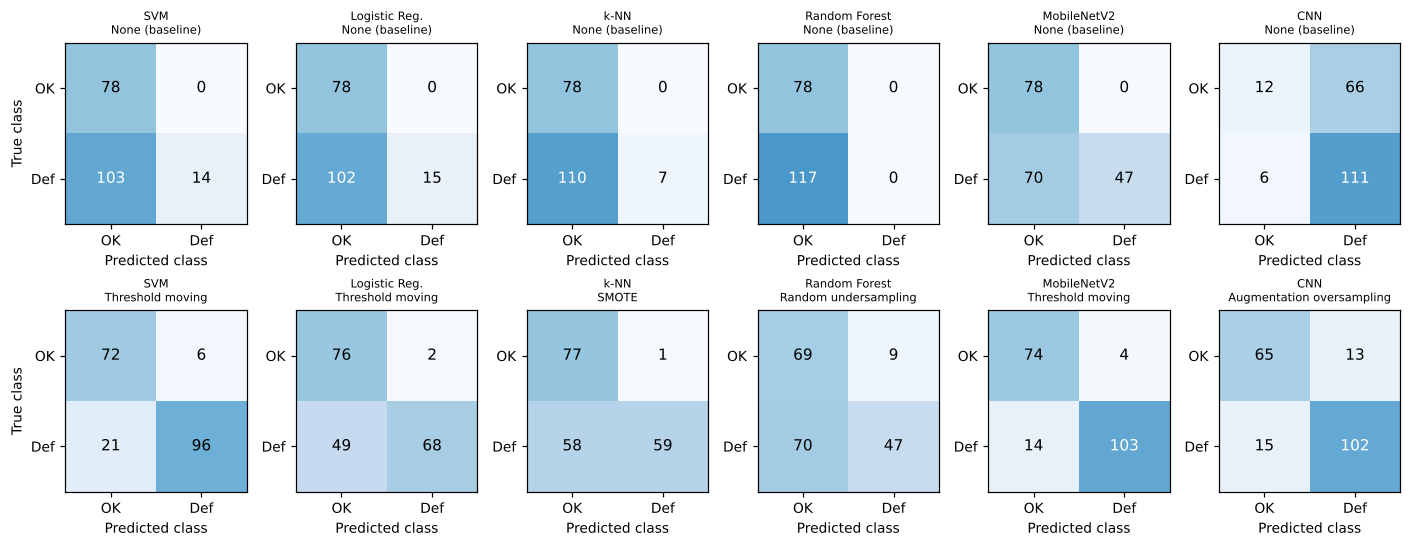

In [42]:
# Confusion matrices of the first repetition: baseline (top) and best method (bottom)
fig, axes = plt.subplots(2, len(order), figsize=(2.15 * len(order), 5.0))
for j, m in enumerate(order):
    for i, method in enumerate(("none", best20.loc[m, "method"])):
        run = raw[(raw.tag == "main") & (raw.model == m) & (raw.ratio == "20")
                  & (raw.rep == 0) & (raw.method == method)].iloc[0]
        pred = (probs[("main", m, "20", 0, method)] >= run.threshold).astype(int)
        cm = confusion_matrix(y_true, pred, labels=[0, 1])
        ax = axes[i, j]
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=len(y_true))
        for a in range(2):
            for b in range(2):
                ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=10,
                        color="white" if cm[a, b] > len(y_true) / 2 else "black")
        ax.set_xticks([0, 1], ["OK", "Def"])
        ax.set_yticks([0, 1], ["OK", "Def"])
        ax.set_xlabel("Predicted class")
        if j == 0:
            ax.set_ylabel("True class")
        ax.set_title(f"{MODEL_SHORT[m]}\n{METHOD_LABELS[method]}", fontsize=7.5)
fig.tight_layout()
plt.show()

### Observations
- **Threshold moving** recovers most of the missed defects for the SVM and MobileNetV2, at the cost of a few extra rejections of good castings.
- **SMOTE** is best for k-NN and **random undersampling** for the Random Forest, although the forest stays well behind.
- For the **CNN**, augmentation oversampling mainly fixes the good castings it was wrongly rejecting.
- Defect precision stays above 0.84 for every best method, so most new alerts are real defects.

## 16.4 Threshold Moving

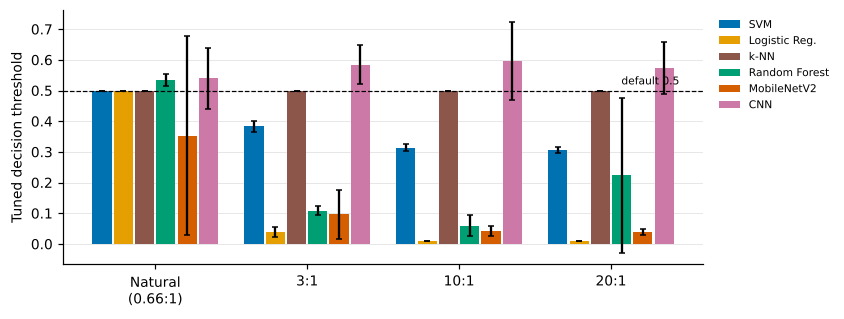

Mean tuned threshold (chosen on the validation set)


ratio,natural,3,10,20
model,,,,
SVM,0.50,0.38,0.31,0.31
LogReg,0.50,0.04,0.01,0.01
KNN,0.50,0.50,0.50,0.50
RandomForest,0.53,0.11,0.06,0.22
MobileNetV2,0.35,0.10,0.04,0.04
CNN,0.54,0.58,0.60,0.57


In [43]:
tm = raw[(raw.tag == "main") & (raw.method == "threshold_moving")]
fig, ax = plt.subplots(figsize=(7.5, 3.0))
width = 0.84 / len(order)
for k, m in enumerate(order):
    g = tm[tm.model == m].groupby("ratio").threshold.agg(["mean", "std"]).reindex(ratios)
    xk = np.arange(len(ratios)) + (k - (len(order) - 1) / 2) * width
    ax.bar(xk, g["mean"], width * 0.9, yerr=g["std"], capsize=2, color=MODEL_COLORS[m], label=MODEL_SHORT[m])
ax.axhline(0.5, color="black", lw=0.8, ls="--")
ax.text(3.45, 0.52, "default 0.5", fontsize=7, ha="right")
ax.set_xticks(range(len(ratios)), [ratio_ticks[r] for r in ratios])
ax.set_ylabel("Tuned decision threshold")
ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
style_axes(ax)
plt.show()

print("Mean tuned threshold (chosen on the validation set)")
tm.groupby(["model", "ratio"]).threshold.mean().unstack()[ratios].reindex(order).round(2)

### Observations
For the SVM, Logistic Regression and MobileNetV2, the tuned threshold falls as imbalance grows. This makes the shift of the decision boundary visible. Very low thresholds such as 0.01 work on this test set but would need re-checking if the defect rate or imaging conditions change. The CNN thresholds stay slightly above 0.5 because its errors fall on the OK class.

## 16.5 Why Some Methods Had No Effect

In [44]:
# Methods whose predictions were identical to the baseline (Holm-adjusted p = 1)
no_effect = stat_table[stat_table.holm_p == 1.0]
no_effect.assign(Model=no_effect.model.map(model_names), Method=no_effect.method.map(METHOD_LABELS))[["Model", "Method", "mean_diff_vs_none"]]

,Model,Method,mean_diff_vs_none
3,SVM,Class weighting,0.0
4,SVM,Random oversampling,0.0
12,k-NN,Class weighting,0.0
13,k-NN,Random oversampling,0.0
14,k-NN,Threshold moving,0.0


**SVM (Ablation C).** Class weights scale the penalty *C* for training errors of each class, and duplicating a sample has the same effect. With *C* = 10 the training data are separated with almost no errors, so the weights have nothing to act on. Ablation C repeats the comparison for several values of *C*.

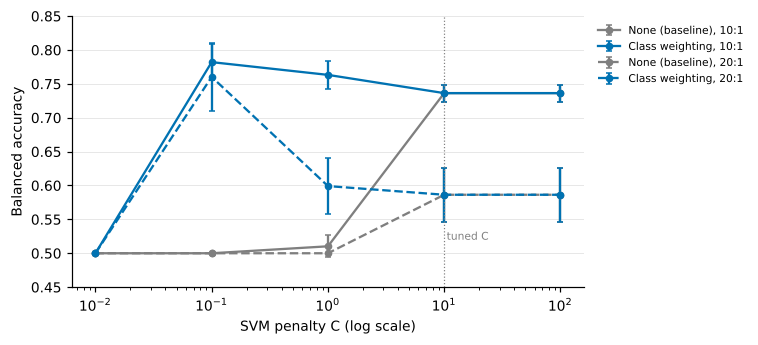

ratio            10                  20       
method class_weight   none class_weight   none
C                                             
0.01          0.500  0.500        0.500  0.500
0.10          0.782  0.500        0.760  0.500
1.00          0.763  0.510        0.599  0.500
10.00         0.736  0.736        0.586  0.586
100.00        0.736  0.736        0.586  0.586

In [45]:
svm_c["C"] = svm_c.tag.str.replace("svmC_", "").astype(float)
g = svm_c.groupby(["C", "ratio", "method"]).balanced_accuracy.agg(["mean", "std"]).reset_index()
fig, ax = plt.subplots(figsize=(6, 3.2))
for ratio, ls in (("10", "-"), ("20", "--")):
    for method in ("none", "class_weight"):
        s = g[(g.ratio == ratio) & (g.method == method)].sort_values("C")
        ax.errorbar(s.C, s["mean"], yerr=s["std"], ls=ls, marker="o", ms=4, capsize=2,
                    color=METHOD_COLORS[method], label=f"{METHOD_LABELS[method]}, {ratio}:1")
ax.set_xscale("log")
ax.axvline(10, color="grey", lw=0.8, ls=":")
ax.text(10.5, 0.52, "tuned C", fontsize=7, color="grey")
ax.set(xlabel="SVM penalty C (log scale)", ylabel="Balanced accuracy", ylim=(0.45, 0.85))
ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
style_axes(ax)
plt.show()
g.pivot_table(index="C", columns=["ratio", "method"], values="mean").round(3)

**k-NN (Ablation D).** With *k* = 1 the model copies the label of the closest training image. Duplicated defects sit at the same position, class weights rescale a vote that is already 0 or 1, and a 0-or-1 output gives the threshold nothing to move. Ablation D repeats the main methods with more neighbours.

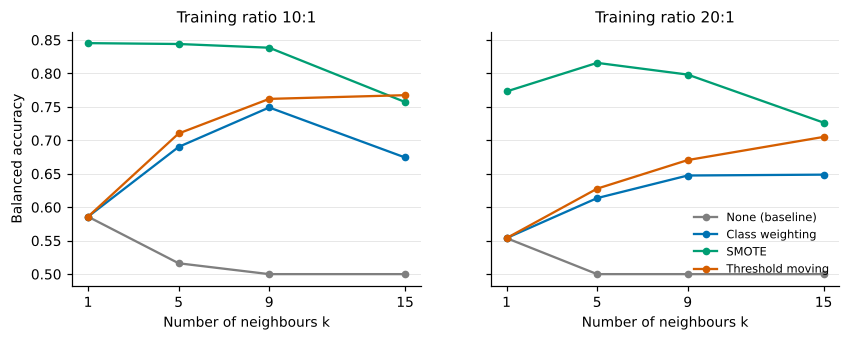

In [46]:
knn = raw[raw.tag.str.startswith("knnk_")].copy()
knn["k"] = knn.tag.str.replace("knnk_", "").astype(int)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0), sharey=True)
for ax, ratio in zip(axes, ("10", "20")):
    g = knn[knn.ratio == ratio].groupby(["k", "method"]).balanced_accuracy.mean().unstack()
    for method in ("none", "class_weight", "smote", "threshold_moving"):
        ax.plot(g.index, g[method], marker="o", ms=4, color=METHOD_COLORS[method], label=METHOD_LABELS[method])
    ax.set_xticks(g.index)
    ax.set(xlabel="Number of neighbours k", title=f"Training ratio {ratio}:1")
    style_axes(ax)
axes[0].set_ylabel("Balanced accuracy")
axes[1].legend(frameon=False, fontsize=7.5, loc="lower right")
plt.show()

### Observations
- With a small penalty (*C* = 0.1), class weighting helps the SVM a lot. The benefit shrinks as *C* grows and disappears at the tuned *C* = 10. Cost-sensitive learning only helps when the model makes training errors.
- With more neighbours, the baseline falls to about 0.5 because OK images outvote the defects. Class weighting and threshold moving then start to work for k-NN. SMOTE stays the best method in almost every case, and threshold moving is ahead only at *k* = 15 and 10:1.

# 17. Classical Versus Neural Models

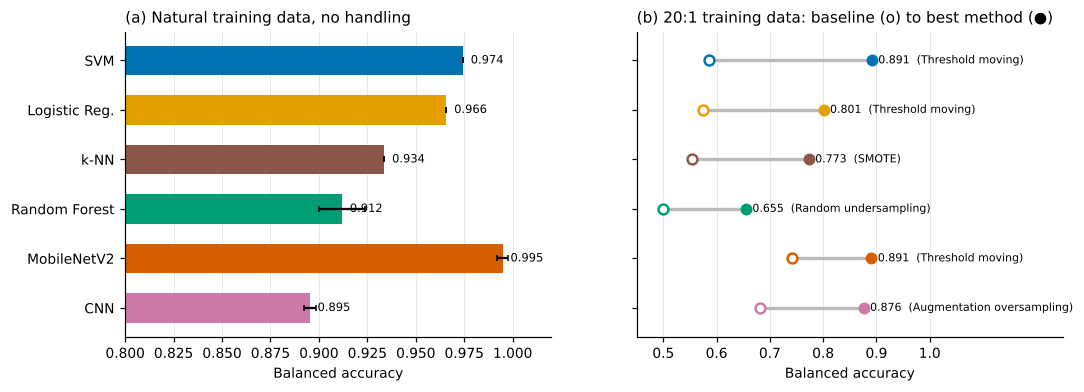

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
ypos = np.arange(len(order))[::-1]
ax = axes[0]
ax.barh(ypos, nat.balanced_accuracy, xerr=nat.balanced_accuracy_sd, capsize=2, height=0.6,
        color=[MODEL_COLORS[m] for m in order])
for y_, v in zip(ypos, nat.balanced_accuracy):
    ax.text(v + 0.004, y_, f"{v:.3f}", va="center", fontsize=7.5)
ax.set_xlim(0.8, 1.02)
ax.set_yticks(ypos, [MODEL_SHORT[m] for m in order])
ax.set_xlabel("Balanced accuracy")
ax.set_title("(a) Natural training data, no handling", loc="left")
ax = axes[1]
for y_, m in zip(ypos, order):
    b, bm = row(m, "20", "none").balanced_accuracy, best20.loc[m]
    ax.plot([b, bm.balanced_accuracy], [y_, y_], color="#BBBBBB", lw=2.2, zorder=1)
    ax.scatter([b], [y_], s=42, facecolor="white", edgecolor=MODEL_COLORS[m], lw=1.6, zorder=2)
    ax.scatter([bm.balanced_accuracy], [y_], s=46, color=MODEL_COLORS[m], zorder=3)
    ax.text(max(b, bm.balanced_accuracy) + 0.012, y_, f"{bm.balanced_accuracy:.3f}  ({METHOD_LABELS[bm.method]})",
            va="center", fontsize=7.2)
ax.set_xlim(0.45, 1.25)
ax.set_xticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_xlabel("Balanced accuracy")
ax.set_title("(b) 20:1 training data: baseline (o) to best method (●)", loc="left")
for a in axes:
    a.grid(axis="x", color="#E5E5E5", lw=0.6)
    a.spines[["top", "right"]].set_visible(False)
    a.set_axisbelow(True)
plt.show()

In [48]:
# Best classical set-up (SVM) against the best neural set-up (MobileNetV2) at each imbalanced ratio
# (Tables 19 and 20 of the report)
rows = []
for r in ("3", "10", "20"):
    svm_best = best[(best.model == "SVM") & (best.ratio == r)].iloc[0]
    mnv2_best = best[(best.model == "MobileNetV2") & (best.ratio == r)].iloc[0]
    rows.append({"Ratio": ratio_names[r],
                 "SVM method": METHOD_LABELS[svm_best.method],
                 "SVM BA": f"{svm_best.balanced_accuracy:.3f} ± {svm_best.balanced_accuracy_sd:.3f}",
                 "MobileNetV2 method": METHOD_LABELS[mnv2_best.method],
                 "MobileNetV2 BA": f"{mnv2_best.balanced_accuracy:.3f} ± {mnv2_best.balanced_accuracy_sd:.3f}",
                 "Neural lead": f"{mnv2_best.balanced_accuracy - svm_best.balanced_accuracy:+.3f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

print("Median time of one run (seconds, this computer)")
raw[raw.tag == "main"].groupby("model").seconds.median().reindex(order).round(2).to_frame("seconds")

Ratio,SVM method,SVM BA,MobileNetV2 method,MobileNetV2 BA,Neural lead
3:1,Threshold moving,0.939 ± 0.010,Augmentation oversampling,0.984 ± 0.015,+0.044
10:1,Threshold moving,0.914 ± 0.009,Threshold moving,0.934 ± 0.018,+0.020
20:1,Threshold moving,0.891 ± 0.033,Threshold moving,0.891 ± 0.019,-0.001


Median time of one run (seconds, this computer)


,seconds
model,
SVM,0.06
LogReg,0.03
KNN,0.03
RandomForest,0.92
MobileNetV2,3.79
CNN,135.74


### Learning curves of the neural models

Early stopping restores the epoch with the highest validation ROC-AUC for MobileNetV2 and the lowest validation loss for the CNN (dotted line).

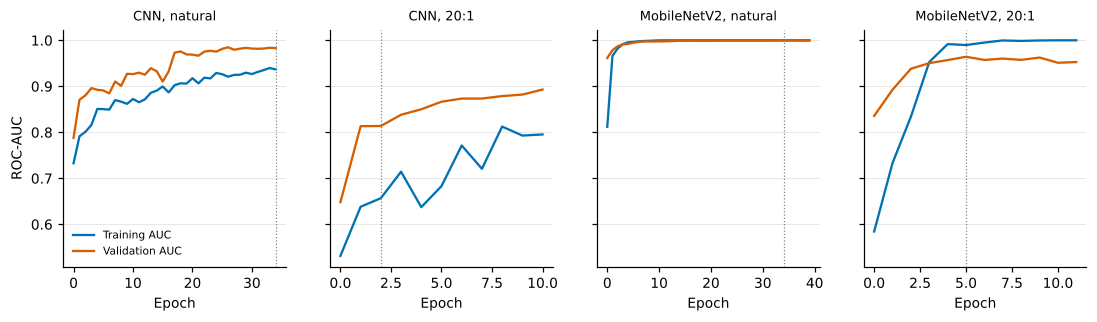

MobileNetV2 head: median best epoch 21 (interquartile range 15 to 28), 120 runs


In [49]:
keys = [("main", "CNN", "natural", 0, "none"), ("main", "CNN", "20", 0, "none"),
        ("main", "MobileNetV2", "natural", 0, "none"), ("main", "MobileNetV2", "20", 0, "none")]
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, k in zip(axes, keys):
    h = histories[k]
    ax.plot(h["auc"], color="#0072B2", label="Training AUC")
    ax.plot(h["val_auc"], color="#D55E00", label="Validation AUC")
    restored = int(np.argmin(h["val_loss"])) if k[1] == "CNN" else int(np.argmax(h["val_auc"]))
    ax.axvline(restored, color="grey", ls=":", lw=0.8)
    ax.set_title(f"{k[1]}, {'natural' if k[2] == 'natural' else k[2] + ':1'}", fontsize=8.5)
    ax.set_xlabel("Epoch")
    style_axes(ax)
axes[0].set_ylabel("ROC-AUC")
axes[0].legend(frameon=False, fontsize=7)
plt.show()

# Epoch chosen by early stopping for every MobileNetV2 run in the main experiment (counted from 1)
best_epochs = [int(np.argmax(h["val_auc"])) + 1 for k, h in histories.items() if k[0] == "main" and k[1] == "MobileNetV2"]
q1, med, q3 = np.percentile(best_epochs, [25, 50, 75])
print(f"MobileNetV2 head: median best epoch {med:.0f} (interquartile range {q1:.0f} to {q3:.0f}), {len(best_epochs)} runs")

### Observations
- Without handling, MobileNetV2 degrades the least because its pretrained ImageNet features already separate the classes.
- With the best handling method for each model, the gap closes. At 20:1 the SVM and MobileNetV2 are effectively tied, but MobileNetV2 varies less between repetitions and the SVM is far cheaper to run.
- The CNN curve is still rising at the 35-epoch limit, so it had not fully converged on a CPU budget.

# 18. Effect of Image Processing and Feature Choice (Ablations A and B)

## 18.1 Ablation A: Image-Processing Variants

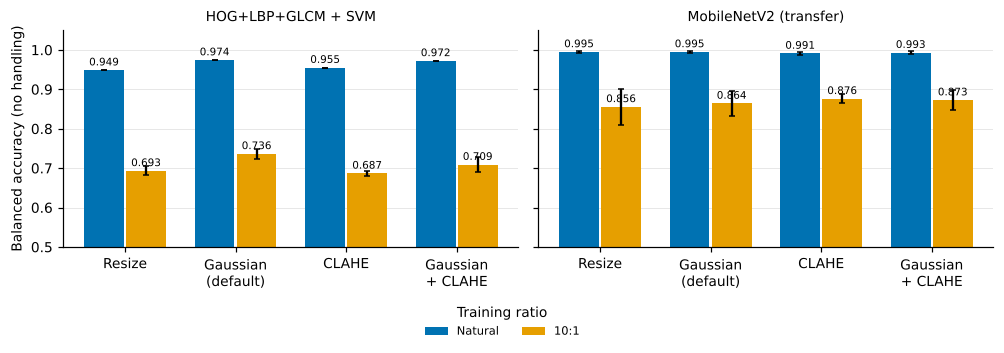

In [50]:
pre = raw[raw.tag.str.startswith("pre_") & (raw.method == "none")]
modes = ["resize", "gaussian", "clahe", "gaussian_clahe"]
mode_names = ["Resize", "Gaussian\n(default)", "CLAHE", "Gaussian\n+ CLAHE"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2), sharey=True)
for ax, m in zip(axes, ("SVM", "MobileNetV2")):
    for k, (ratio, col) in enumerate((("natural", "#0072B2"), ("10", "#E69F00"))):
        d = pre[(pre.model == m) & (pre.ratio == ratio)].groupby("tag").balanced_accuracy.agg(["mean", "std"])
        d = d.reindex([f"pre_{mode}" for mode in modes])
        xk = np.arange(len(modes)) + (k - 0.5) * 0.38
        bars = ax.bar(xk, d["mean"], 0.36, yerr=d["std"], capsize=2, color=col,
                      label="Natural" if ratio == "natural" else "10:1")
        for bar, v in zip(bars, d["mean"]):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.012, f"{v:.3f}", ha="center", fontsize=6.8)
    ax.set_xticks(range(len(modes)), mode_names)
    ax.set_ylim(0.5, 1.05)
    ax.set_title(MODEL_LABELS[m], fontsize=9)
    style_axes(ax)
axes[0].set_ylabel("Balanced accuracy (no handling)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, title="Training ratio", fontsize=7.5, ncol=2,
           loc="lower center", bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

## 18.2 Ablation B: Handcrafted Feature Groups (SVM)

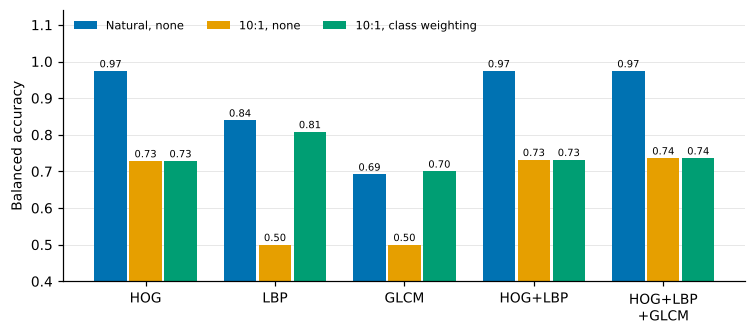

In [51]:
feat = raw[raw.tag.str.startswith("feat_")]
groups = ["hog", "lbp", "glcm", "hog+lbp", "hog+lbp+glcm"]
group_names = ["HOG", "LBP", "GLCM", "HOG+LBP", "HOG+LBP\n+GLCM"]
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, (ratio, method, col, lab) in enumerate((("natural", "none", "#0072B2", "Natural, none"),
                                               ("10", "none", "#E69F00", "10:1, none"),
                                               ("10", "class_weight", "#009E73", "10:1, class weighting"))):
    vals = [feat[(feat.tag == f"feat_{g_}") & (feat.ratio == ratio) & (feat.method == method)].balanced_accuracy.mean()
            for g_ in groups]
    bars = ax.bar(np.arange(len(groups)) + (k - 1) * 0.27, vals, 0.25, color=col, label=lab)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=6.5)
ax.set_xticks(range(len(groups)), group_names)
ax.set_ylim(0.4, 1.14)
ax.set_ylabel("Balanced accuracy")
ax.legend(frameon=False, fontsize=7.5, ncol=3, loc="upper left")
style_axes(ax)
plt.show()

### Observations
- The 3 × 3 Gaussian filter is the best variant for the SVM, both on the natural data and at 10:1. CLAHE does not help, because it also strengthens background texture. MobileNetV2 changes by at most about 0.02 between variants, so the Gaussian pipeline is kept for both pathways.
- HOG carries most of the information. LBP and GLCM are weak on their own, and the full combination gives a small further gain at 10:1.
- Class weighting helps the LBP-only SVM, whose small feature space is not separable. This supports the explanation in Section 16.5.

# 19. Most Reliable Combination (Table 21 of the report)

Mean over the three imbalanced ratios (3:1, 10:1 and 20:1), so a combination must work at every level of imbalance to rank highly.

In [52]:
overall = (main[main.ratio != "natural"].groupby(["model", "method"])
           [["balanced_accuracy", "recall_defective", "recall_ok", "mcc"]].mean()
           .sort_values("balanced_accuracy", ascending=False).reset_index())
top10 = overall.head(10).assign(model=lambda d: d.model.map(model_names), method=lambda d: d.method.map(METHOD_LABELS))
top10.index = range(1, 11)
top10.columns = ["Model", "Method", "Balanced accuracy", "Recall Def.", "Recall OK", "MCC"]
top10.round(3)

,Model,Method,Balanced accuracy,Recall Def.,Recall OK,MCC
1,MobileNetV2,Threshold moving,0.929,0.916,0.943,0.856
2,MobileNetV2,Augmentation oversampling,0.920,0.847,0.992,0.832
3,SVM,Threshold moving,0.915,0.894,0.936,0.822
4,MobileNetV2,SMOTE,0.913,0.838,0.988,0.817
5,MobileNetV2,Random oversampling,0.911,0.831,0.990,0.813
6,MobileNetV2,Class weighting,0.910,0.840,0.979,0.813
7,MobileNetV2,Random undersampling,0.901,0.852,0.949,0.796
8,CNN,Augmentation oversampling,0.894,0.878,0.909,0.778
9,Logistic Regression,Threshold moving,0.878,0.796,0.960,0.751
10,MobileNetV2,None (baseline),0.860,0.724,0.997,0.729


### Observations
**Gaussian preprocessing + MobileNetV2 + threshold moving** has the highest mean balanced accuracy, with strong recall on both classes, so it is used in the prototype. The best classical combination, **Gaussian + HOG/LBP/GLCM + SVM + threshold moving**, ranks third and is a strong lightweight alternative. These rankings come from test-set summaries, so they still need confirmation on independent data.

# 20. Deployed Models

The best neural and classical pipelines were retrained on the full training split by `scripts/train_final_models.py`, with thresholds tuned on the validation set, and saved in `models/`. The table below reproduces Table 22 of the report. The dashboard (`streamlit run app.py`) loads these two pipelines.

In [53]:
import json
card = json.loads((CFG.model_dir / "model_card.json").read_text())
rows = {}
for key, info in card["pipelines"].items():
    m = info["test_metrics"]
    rows[info["name"]] = {"threshold": info["threshold"], "balanced_accuracy": m["balanced_accuracy"],
                          "recall_defective": m["recall_defective"], "recall_ok": m["recall_ok"],
                          "precision_defective": m["precision_defective"], "f1_defective": m["f1_defective"],
                          "mcc": m["mcc"], "missed defects (FN)": m["fn"], "false alarms (FP)": m["fp"]}
deployed = pd.DataFrame(rows).T.round(3)
deployed[["missed defects (FN)", "false alarms (FP)"]] = deployed[["missed defects (FN)", "false alarms (FP)"]].astype(int)
deployed

,threshold,balanced_accuracy,recall_defective,recall_ok,precision_defective,f1_defective,mcc,missed defects (FN),false alarms (FP)
SVM (HOG + LBP + GLCM),0.5,0.974,0.974,0.974,0.983,0.979,0.947,3,2
MobileNetV2 (transfer learning),0.3,0.994,1.000,0.987,0.992,0.996,0.989,0,1


### Grad-CAM: where does the deployed MobileNetV2 look?

Grad-CAM highlights the image regions that increased the predicted probability of a defect (warm colours).

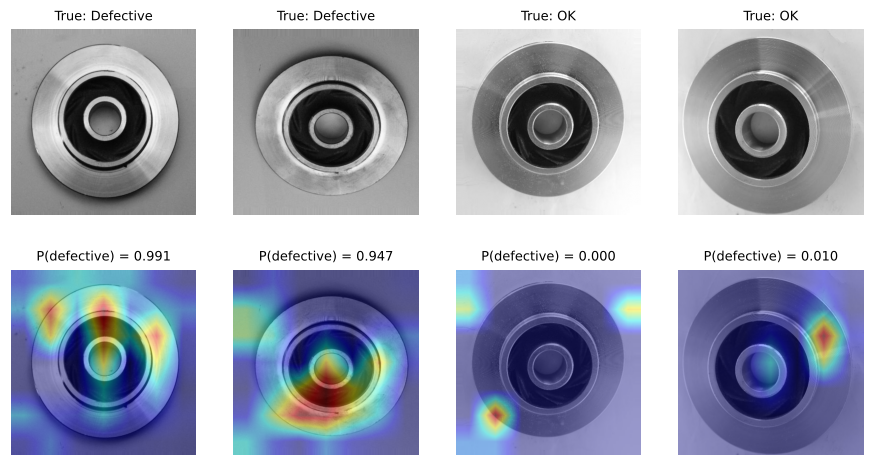

In [54]:
from casting_imbalance.inference import MobileNetPipeline
mnet = MobileNetPipeline.load(CFG.model_dir)

picks = list(test_df[test_df.label == 1].index[:2]) + list(test_df[test_df.label == 0].index[:2])
fig, axes = plt.subplots(2, 4, figsize=(10, 5.2))
for j, i in enumerate(picks):
    img = cv2.imread(test_df.path[i], cv2.IMREAD_GRAYSCALE)
    p = mnet.predict_proba([img])[0]
    cam = mnet.grad_cam(img)
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    overlay = (0.6 * np.repeat(img[..., None], 3, -1) + 0.4 * heat).astype(np.uint8)
    axes[0, j].imshow(img, cmap="gray")
    axes[0, j].set_title(f"True: {CLASS_NAMES[test_df.label[i]]}", fontsize=8.5)
    axes[1, j].imshow(overlay)
    axes[1, j].set_title(f"P(defective) = {p:.3f}", fontsize=8.5)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.show()

### Observations
- The deployed MobileNetV2 catches every defective test casting and rejects only one good casting.
- For defective castings, the Grad-CAM maps focus on the blade area and inner rim. Some activation also falls on the background, which, together with the brightness difference found in Section 3.4, suggests the model may partly use image-wide cues. For OK castings the predicted probability is close to zero, so their maps are weak and should not be interpreted.

# 21. Summary

```text
                     SAME 195 TEST IMAGES
                              │
         ┌────────────────────┴────────────────────┐
         ▼                                         ▼
 HOG + LBP + GLCM → PCA                 MobileNetV2 embeddings / CNN
 SVM, LogReg, k-NN, RF                  (learned features)
         │                                         │
 Imbalance pushes scores down. Defect recall collapses at 20:1
         │                                         │
 Best fix: threshold moving (SVM, LR)    Best fix: threshold moving (MNV2),
           SMOTE (k-NN), RUS (RF)                  augmentation (CNN)
         └────────────────────┬────────────────────┘
                              ▼
   Most reliable: Gaussian + MobileNetV2 + threshold moving
   Best classical: Gaussian + HOG/LBP/GLCM + SVM + threshold moving
```

1. Accuracy hides the effect of imbalance. Balanced accuracy and the class recalls show it (Section 15).
2. Most models still rank defects correctly (high ROC-AUC). The default threshold is what fails (Section 15.3).
3. The best handling method depends on how each model makes its decision, and the differences are statistically significant (Section 16).
4. Pretrained features make MobileNetV2 the most robust model, while the SVM with threshold moving is almost as good at a fraction of the cost (Sections 17 and 19).